# M12d · SVD et analyse en composantes principales — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m12d_svd_acp/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M12d.1 à M12d.13, M12d.20, M12d.21 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M12d.26 | La SVD par les valeurs propres de AᵀA · `svd` | 🔨 | ★★ | 40 |
|  | M12d.27 | Approximation de rang faible et conditionnement · `low_rank_approximation, condition_number` | 🔨 | ★ | 20 |
|  | M12d.28 | La pseudo-inverse · `pinv` | 🔨 | ★ | 15 |
|  | M12d.29 | Les axes principaux d'une matrice de covariance, et la variance expliquée · `principal_axes, explained_variance_ratio` | 🔨 | ★★ | 25 |
|  | M12d.30 | `np.linalg.svd`, `np.linalg.cond` et `sklearn.decomposition.PCA` contre tes fonctions : les signes | 📦 | ★ | 15 |
| B | M12d.31 | Prédire l'allure des valeurs singulières d'une image, et le rang qui suffit | 🔮 | ★ | 10 |
|  | M12d.32 | Compresser une image du domaine public : l'erreur en fonction du rang | 🔬 | ★★ | 20 |
|  | M12d.33 | La SVD par AᵀA contre `np.linalg.svd` : ce qu'on perd quand κ est grand | 🔬 | ★★ | 20 |
|  | M12d.34 | La SVD en images : Vᵀ, Σ puis U appliqués au cercle unité, étape par étape | 🎨 | ★ | 20 |
| C | M12d.35 | Chasse à l'erreur : une ACP sans centrer, n et n − 1 mélangés, des axes lus en lignes au lieu de colonnes | 🐛 | ★ | 15 |
|  | M12d.36 | Un test : la reconstruction de rang plein redonne X, et l'erreur décroît avec k | 🛠️ | ★ | 15 |
|  | M12d.37 | Défi : compresser une image centrée en gardant 93,5 % de son énergie avec au plus 5 % des nombres | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : SVD à la main, SVD compacte, image du cercle unité, approximation de rang faible et son erreur, coût de stockage, pseudo-inverse, conditionnement, axes principaux, scores et reconstruction, variance expliquée, ACP par la SVD et en grande dimension, voisinages de t-SNE, anomalies, changement d'unités.
- Écrire les six fonctions de `mymath/svd_pca.py` et les tester, puis comparer avec NumPy et scikit-learn.
- Prédire et mesurer la compression d'une photo, mesurer la précision de la SVD par AᵀA, dessiner la SVD, chasser des erreurs dans une ACP, écrire un test de propriétés, relever un défi de compression.

**Rappel express.** $\mathbf{A} = \mathbf{U}\mathbf{S}\mathbf{V}^\top = \sum_i s_i\mathbf{u}_i\mathbf{v}_i^\top$, $s_i = \sqrt{\lambda_i(\mathbf{A}^\top\mathbf{A})}$, $\mathbf{u}_i = \mathbf{A}\mathbf{v}_i/s_i$ ; $\lVert \mathbf{A}\mathbf{x} \rVert \le s_1\lVert \mathbf{x} \rVert$ ; $\lVert \mathbf{A} - \mathbf{A}_k \rVert_F^2 = \sum_{i > k} s_i^2$, $k(m + n + 1)$ nombres ; $\mathbf{A}^+ = \mathbf{V}\mathbf{S}^{-1}\mathbf{U}^\top$, $\mathbf{x}^+ = \mathbf{A}^+\mathbf{b}$ ; $\kappa = s_{\max}/s_{\min}$, $\kappa(\mathbf{A}^\top\mathbf{A}) = \kappa^2$ ; $\mathbf{C} = \frac{1}{n-1}\mathbf{X}_c^\top\mathbf{X}_c$, axes = vecteurs propres, $\lambda_j = s_j^2/(n - 1)$ ; scores $\mathbf{Z} = \mathbf{X}_c\mathbf{W}_k$, $\hat{\mathbf{X}} = \mathbf{Z}\mathbf{W}_k^\top + \boldsymbol{\mu}$ ; erreur moyenne $\frac{n-1}{n}\sum_{j > k}\lambda_j$ ; perplexité $2^{H}$.

## Partie 0 · Vérifier tes exercices papier (✏️ M12d.1 à M12d.13, 🔗 M12d.20 et M12d.21)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0, -2, 5]` pour un vecteur (les valeurs singulières et les variances par ordre décroissant), une liste de lignes `[[1, 0], [-2, 3]]` pour une matrice, ou `True` / `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy) from the statements
import numpy as np
import sympy


def exact(values):
    """SymPy or NumPy numbers as Python ints when whole, else floats."""
    return [int(v) if v == int(v) else float(v) for v in values]


def matrix(M):
    """A matrix as a list of rows of exact numbers."""
    return [exact(row) for row in sympy.Matrix(M).tolist()]


def floats(M):
    """A matrix as a list of rows of floats."""
    return [[float(v) for v in row] for row in sympy.Matrix(M).tolist()]


def qf(M, w):
    """The quadratic form wᵀ M w."""
    w = sympy.Matrix(w)
    return (w.T * M * w)[0]


V, sq = sympy.Matrix, sympy.sqrt
A_1 = V([[10, 10], [5, 2]])                                                                 # M12d.1
V1_1, V2_1 = V([11, 10]) / sq(221), V([-10, 11]) / sq(221)
U1_1 = A_1 * V1_1 / 15
assert A_1.T * A_1 * V([11, 10]) == 225 * V([11, 10]) and A_1.T * A_1 * V([-10, 11]) == 4 * V([-10, 11])
A_2 = V([[2, -10], [10, -50], [11, -55]])                                                   # M12d.2
V1_2, V2_2 = V([-1, 5]) / sq(26), V([5, 1]) / sq(26)
U1_2 = A_2 * V1_2 / (15 * sq(26))
assert A_2 * V([5, 1]) == V([0, 0, 0])
B_3 = V([[1, 8], [4, -4]])                                                                  # M12d.3
V1_3 = V([-1, 8]) / sq(65)
U1_3 = B_3 * V1_3 / 9
assert B_3.T * B_3 * V([-1, 8]) == 81 * V([-1, 8])
A_4 = V([[4, 2, 1], [4, 2, -1], [1, 4, 0]])                                                 # M12d.4
V1_4 = V([5, 4, 0]) / sq(41)
U1_4 = A_4 * V1_4 / 7
A1_4 = 7 * U1_4 * V1_4.T
assert A_4.T * A_4 * V([5, 4, 0]) == 49 * V([5, 4, 0])
A_6 = V([[2, -8, 16], [5, -20, 40]])                                                        # M12d.6
P_6 = A_6.T / 2349
assert sympy.simplify(A_6 * P_6 * A_6 - A_6) == sympy.zeros(2, 3)
R_7 = V([[8, 3], [5, 2]])                                                                   # M12d.7
KAPPA_7 = 51 + 10 * sq(26)
AMPL_7 = ((R_7.solve(V([sympy.Rational(1, 100), 0]))).norm() / (R_7.solve(V([14, 9]))).norm()) / (sympy.Rational(1, 100) / V([14, 9]).norm())
assert abs(float(KAPPA_7) - np.linalg.cond(np.array([[8.0, 3.0], [5.0, 2.0]]))) < 1e-9
X_8 = V([[10, 8, 3], [9, 14, 7], [15, 4, 9], [10, 6, 4], [16, 11, 6], [18, 10, 6], [20, 10, 7]])   # M12d.8
MU_8 = V([sum(X_8[:, j]) / 7 for j in range(3)])
XC_8 = X_8 - sympy.ones(7, 1) * MU_8.T
C_8 = XC_8.T * XC_8 / 6
U1_8, U2_8, U3_8 = V([4, 0, 1]) / sq(17), V([0, 1, 0]), V([-1, 0, 4]) / sq(17)
assert C_8 * U1_8 == 20 * U1_8 and C_8 * U2_8 == 11 * U2_8 and C_8 * U3_8 == 3 * U3_8
D7_9 = X_8.row(6).T - MU_8                                                                  # M12d.9
REC7_9 = MU_8 + U1_8.dot(D7_9) * U1_8 + U2_8.dot(D7_9) * U2_8
LAMBDA_10 = [sympy.Rational(v, 10) for v in (96, 48, 24, 11, 7, 6, 5, 3)]                   # M12d.10
X_11 = V([[3, 1, 3], [3, 4, 6], [9, 4, 8], [9, 7, 3]])                                       # M12d.11
MU_11 = V([sum(X_11[:, j]) / 4 for j in range(3)])
XC_11 = X_11 - sympy.ones(4, 1) * MU_11.T
V1_11 = V([5, 3, 1]) / sq(35)
assert [XC_11.T * XC_11 * V(d) == k * V(d) for d, k in (([5, 3, 1], 48), ([0, -1, 3], 18), ([-2, 3, 1], 6))] == [True] * 3
X_12 = V([[8, 8, 4, 6, 5], [3, 8, 3, 2, 7], [4, 2, 2, 4, 9]])                                # M12d.12
MU_12 = V([sum(X_12[:, j]) / 3 for j in range(5)])
XC_12 = X_12 - sympy.ones(3, 1) * MU_12.T
V1_12 = XC_12.T * V([1, 0, -1]) / (XC_12.T * V([1, 0, -1])).norm()
assert (XC_12 * XC_12.T) * V([1, 0, -1]) == 38 * V([1, 0, -1])
P1_13 = [sympy.Rational(4, 7), sympy.Rational(2, 7), sympy.Rational(1, 7)]                  # M12d.13
H_13 = -sum(p * sympy.log(p, 2) for p in P1_13)


def err_20(x):                                                                              # M12d.20
    """The reconstruction error of x with the first two axes of the cloud of M12d.8: its squared score on u₃."""
    return U3_8.dot(x - MU_8) ** 2


D_21 = sympy.diag(1, 1, 3)                                                                  # M12d.21
_vals_21 = (D_21 * C_8 * D_21).eigenvects()
_top_21 = max(_vals_21, key=lambda e: float(e[0]))[2][0]
U1_21 = _top_21 / _top_21.norm()
U1_21 = U1_21 if max(U1_21, key=lambda v: abs(float(v))) > 0 else -U1_21
_s_21 = sympy.diag(*[1 / sq(C_8[i, i]) for i in range(3)])
CORR_21 = _s_21 * C_8 * _s_21

**Ex M12d.1 — La SVD d'une matrice 2 × 2 à la main, par AᵀA**

In [3]:
wbm.record("M12d.1a", matrix(A_1.T * A_1), mistakes={"AᵀA : les produits scalaires des COLONNES de A, pas des lignes": matrix(A_1 * A_1.T)})
wbm.record("M12d.1b", [225, 4], mistakes={"l'ordre décroissant : la plus grande d'abord": [4, 225]})
wbm.record("M12d.1c", [15, 2], mistakes={"une valeur singulière est la RACINE d'une valeur propre de AᵀA": [225, 4], "l'ordre décroissant : la plus grande d'abord": [2, 15]})
wbm.record("M12d.1d", exact(V1_1), decimals=4, mistakes={"un vecteur unitaire : divise par sa norme": [11, 10], "la convention de signe : la coordonnée de plus grande valeur absolue positive": exact(-V1_1), "v₁ va avec la plus GRANDE valeur propre de AᵀA": exact(V2_1)})
wbm.record("M12d.1e", exact(V2_1), decimals=4, mistakes={"la convention de signe : la coordonnée de plus grande valeur absolue positive": exact(-V2_1)})
wbm.record("M12d.1f", exact(U1_1), decimals=4, mistakes={"u₁ = A v₁ / s₁ : divise par s₁": exact(A_1 * V1_1), "u₁ = A v₁ / s₁, avec A et non Aᵀ": exact(A_1.T * V1_1 / 15)})
wbm.record("M12d.1g", A_1.det(), mistakes={"ad − bc, pas ad + bc": 70, "le déterminant garde son signe : seule sa valeur absolue est s₁ s₂": 30})
wbm.record("M12d.1h", [float(6 + sq(66)), float(6 - sq(66))], decimals=4, mistakes={"les valeurs propres de A elle-même : les racines de λ² − (tr A) λ + det A": [15.0, 2.0], "l'ordre décroissant : la plus grande d'abord": [float(6 - sq(66)), float(6 + sq(66))]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["f88786699b6e36fbd3c78650072800a99cd77cb101c7122d666915f994092a06", "04591c4e4d0eb865fd14786bf8c41e1bd45b5dd78fe6703d4d411aecfc00f75e", "79ada2ddb05d1f593ddfe751bfb6d2ddbc91f9e7ae3ef463420cd3616a638c18", "3b05c87d0b20731ff01dbbe36df20b9850e0cc60b589b6fd77046d39fbc88531"], "hash": "5eede74d24cb7b01f4e633c0f0a49894c25bae2b7dddb6419230c1fbdc2ef9e8", "id": "M12d.1a", "integer": true, "kind": "array", "mistakes": {"15ed45780a0c37f3fe770f61d5d6c3bd2af4c3e926e03e1075f3e01385803992": "AᵀA : les produits scalaires des COLONNES de A, pas des lignes"}, "shape": [2, 2]}
📝 Ex M12d.1a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["5aba2a76c9625d36923f8a5cb9a28c7a3f3979888c3d174b4cdf40d11b40ce5a", "9c326893f355fbc8baeb9c6de6faef628911f26b8d3afcda79037bec9ceeb8a9"], "hash": "882d9841b9d7c9a03aaedebb539eead6e94d87b50d75b0aeddcad02100eefb06", "id": "M12d.1b", "integer": true, "kind": "array", "mistakes": {"2ebe9ac0f

**Ex M12d.2 — La SVD compacte d'une matrice 3 × 2 de rang 1**

In [4]:
wbm.record("M12d.2a", A_2.rank(), mistakes={"les deux colonnes sont proportionnelles": 2})
wbm.record("M12d.2b", matrix(A_2.T * A_2), mistakes={"AᵀA est de forme (2, 2) : les produits scalaires des colonnes": matrix(A_2 * A_2.T)})
wbm.record("M12d.2c", [5850, 0], mistakes={"l'ordre décroissant : la plus grande d'abord": [0, 5850]})
wbm.record("M12d.2d", float(15 * sq(26)), decimals=4, mistakes={"une valeur singulière est la RACINE d'une valeur propre de AᵀA": 5850.0})
wbm.record("M12d.2e", exact(V1_2), decimals=4, mistakes={"un vecteur unitaire : divise par sa norme": [-1, 5], "la convention de signe : la coordonnée de plus grande valeur absolue positive": exact(-V1_2)})
wbm.record("M12d.2f", exact(U1_2), decimals=4, mistakes={"u₁ = A v₁ / s₁, avec le v₁ de la convention : son signe suit celui de v₁": exact(-U1_2)})
wbm.record("M12d.2g", 5850, fractional="‖A‖²_F est la somme des carrés de tous les éléments, s₁² et non s₁ : un entier.")
wbm.record("M12d.2h", exact(V2_2), decimals=4, mistakes={"la convention de signe : la coordonnée de plus grande valeur absolue positive": exact(-V2_2), "un vecteur unitaire : divise par sa norme": [5, 1]})

WBM_ANSWER {"hash": "0c6681b5033b4386c602a0ccc8a2318390f179eb2765f45b6216a7a71301118d", "id": "M12d.2a", "kind": "int", "magnitude": 0, "mistakes": {"92f0de1f9f3edbef4a04cab6f0098fec186205310e5f065980ce271fe2d2421d": "les deux colonnes sont proportionnelles"}, "sign": 1}
📝 Ex M12d.2a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["1169724c1b5fbe86848c3217e2602fc7761119c37260929dc6365d7d9c4d5484", "89294377cf3e4feb0409b37f5cf8f8a74fb37993d288823d11a0471b927f89f2", "3b6dc690ee5240d0d7ff1d24198a5301065589a7f1f478afe4e8645e9f06d439", "187db2b224de62afded3302fd02801814af625ea025be1c6cf5b92fae519e45d"], "hash": "785907be323f61df556da68c67c0097f804840ab6b27da536da8e39e39bed7df", "id": "M12d.2b", "integer": true, "kind": "array", "mistakes": {"bdec15b9a9a129445d2599983fec976b3e80724ff20cdd214e02608f3cf3edd1": "AᵀA est de forme (2, 2) : les produits scalaires des colonnes"}, "shape": [2, 2]}
📝 Ex M12d.2b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimal

**Ex M12d.3 — Le cercle unité devient une ellipse : axes et demi-axes**

In [5]:
wbm.record("M12d.3a", [9, 4], mistakes={"les demi-axes sont les valeurs singulières, racines des valeurs propres de BᵀB": [81, 16], "l'ordre décroissant : la plus grande d'abord": [4, 9]})
wbm.record("M12d.3b", exact(U1_3), decimals=4, mistakes={"le grand axe est porté par u₁ = B v₁ / s₁, dans l'espace d'arrivée ; v₁ est le point de départ": exact(V1_3), "un vecteur unitaire : divise par sa norme": [7, -4]})
wbm.record("M12d.3c", exact(V1_3), decimals=4, mistakes={"la convention de signe : la coordonnée de plus grande valeur absolue positive": exact(-V1_3), "le point de DÉPART du cercle, v₁, pas son image": exact(U1_3)})
wbm.record("M12d.3d", abs(B_3.det()), mistakes={"une aire est positive : π s₁ s₂ = π |det B|": -36})
wbm.record("M12d.3e", float((B_3 * V([1, 0])).norm()), decimals=4)
wbm.record("M12d.3f", float((B_3 * V([0, 1])).norm()), decimals=4)
wbm.record("M12d.3g", 2.25, decimals=2, mistakes={"le rapport des valeurs singulières, pas de leurs carrés": 81 / 16})
wbm.record("M12d.3h", bool(B_3.det() > 0), mistakes={"le signe du déterminant dit si l'orientation est conservée": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["011f584822b0e1201fee4b3f8c32f3f28e0618083f623a0005e7bfabefe2bc00", "26bf5d9066e883752d60d6261246271d31409d6b8385220b87840e2793c2871e"], "hash": "62df7a8d1c92e243ec65167decce48e00c941a5f069985d3fa181b0bd9f44c5f", "id": "M12d.3a", "integer": true, "kind": "array", "mistakes": {"ee5091195569ca886fe577be668d55820483c240d02e16361d6fd49dc68aaea0": "les demi-axes sont les valeurs singulières, racines des valeurs propres de BᵀB", "f2753f715479e7ccaf168895ebbed1379577198101f310907fc740947ae40329": "l'ordre décroissant : la plus grande d'abord"}, "shape": [2]}
📝 Ex M12d.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 4, "element_coarse": [["2dec08ce662c85542cd79c8e9f508754aa37bdcaaab99c698184ef421b9c62ec"], ["6cc0a422f62a140b4c732d23eb1a2694c90f8bdd18fd0d3b6ddd2be27a6c3085"]], "element_coarse_any": [["ea7fe3923972456c2ad2e7db06d3a0497c4b142cac1c37fd2e0d56163d27660c", "f72d4c103845677d0da3f8e0cc198cda98877ba16132e8afcf32762036d4

**Ex M12d.4 — L'approximation de rang 1 d'une matrice 3 × 3 et son erreur**

In [6]:
wbm.record("M12d.4a", sum(v ** 2 for v in A_4))
wbm.record("M12d.4b", matrix(A_4.T * A_4), mistakes={"AᵀA : les produits scalaires des COLONNES de A": matrix(A_4 * A_4.T)})
wbm.record("M12d.4c", [7.0, float(2 * sq(2)), float(sq(2))], decimals=4, mistakes={"une valeur singulière est la RACINE d'une valeur propre de AᵀA": [49, 8, 2], "l'ordre décroissant : la plus grande d'abord": [float(sq(2)), float(2 * sq(2)), 7.0]})
wbm.record("M12d.4d", exact(V1_4), decimals=4, mistakes={"un vecteur unitaire : divise par sa norme": [5, 4, 0]})
wbm.record("M12d.4e", exact(U1_4), decimals=4, mistakes={"u₁ = A v₁ / s₁ : divise par s₁": exact(A_4 * V1_4)})
wbm.record("M12d.4f", floats(A1_4), decimals=4, mistakes={"A₁ = s₁ u₁ v₁ᵀ : n'oublie pas le facteur s₁": floats(U1_4 * V1_4.T)})
wbm.record("M12d.4g", float(sq(10)), decimals=4, mistakes={"la racine de la somme des CARRÉS des valeurs singulières oubliées": float(3 * sq(2)), "la norme, pas son carré": 10.0})
wbm.record("M12d.4h", float(sympy.Rational(49, 59)), decimals=4, mistakes={"l'énergie se compte avec les CARRÉS des valeurs singulières": float(7 / (7 + 3 * sq(2)))})

WBM_ANSWER {"hash": "90664410e8f6246a8e3fa608e6e694ed549ad333c092f65141d4c7da4bba9262", "id": "M12d.4a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M12d.4a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["4dd94f457e192ed3d4a8cdfff3d79b3e2a7c9e0de6930f90f144e688777e6743", "c19e9047d3abc1e3f42ea0053c90bd89e5c3bfbf2cf2130cbd69e61ed6b632de", "cf174fac1c7c0ca770c4970b4331e4338a9f21b2d2cc2df803049a45d9927e30", "02994f7dd16cc0ce11ba1fd643dc3c75c0d1e028cca323bb2dc7c7ce64329769", "b43aa9f71b9047fbbc804357387471551a9ba1009a84736990aecf3624f35db3", "54390b1df974f35991e0e1acbeaa699cec2273a68607124c492168eba0f10908", "fe5570a2d509a66f354a010de5acde8a57bc32459dfbd53e1e80503af25977e1", "47af2fb5ff600499d45b05a956c023519ceeb2c0274124afbf2611be3d49709b", "70befc4ef98a41f91e2dae56db39bfad81cee9c7d3bf99b6fd79191ae1236856"], "hash": "ae1cae17f8631f993021b88f9c98c2b60612f1d3eff4f48c1d8141a545500121", "id": "M12d.4b", "integer": true, "kind": "array", "mistakes": {"14e6a2dc6b3

**Ex M12d.5 — Compter les nombres stockés : une image en rang k**

In [7]:
wbm.record("M12d.5a", 900 * 1600)
wbm.record("M12d.5b", 40 * (900 + 1600 + 1), mistakes={"k(m + n + 1) : les k valeurs singulières se stockent aussi": 40 * (900 + 1600)})
wbm.record("M12d.5c", float(sympy.Rational(40 * 2501, 900 * 1600)), decimals=4)
wbm.record("M12d.5d", (900 * 1600 - 1) // 2501, mistakes={"le plus grand k tel que k(m + n + 1) < mn : arrondis vers le bas": 576})
wbm.record("M12d.5e", (900 * 1600 * 2 // 100) // 2501, mistakes={"le plus grand k tel que k(m + n + 1) ≤ 0,02 mn : arrondis vers le bas": 12})
wbm.record("M12d.5f", 3 * 40 * 2501)
wbm.record("M12d.5g", 40 * (900 + 4800 + 1), mistakes={"une seule matrice de forme (900, 4 800) : k(m + n + 1) avec n = 4 800": 3 * 40 * 2501})

WBM_ANSWER {"hash": "53dc603a29ee592ebc4810dc7b1b768d757bbe02415951bb5bab070a4e6cc50f", "id": "M12d.5a", "kind": "int", "magnitude": 6, "sign": 1}
📝 Ex M12d.5a : réponse enregistrée (int).
WBM_ANSWER {"hash": "f0e9292c641992269bc7b94fa94fea068ae3ece069374d07f507cc2549c8da7b", "id": "M12d.5b", "kind": "int", "magnitude": 5, "mistakes": {"4d8d3d15aecb25955478614920c7dd5d15a47114f10ee8b091f962bbb646109d": "k(m + n + 1) : les k valeurs singulières se stockent aussi"}, "sign": 1}
📝 Ex M12d.5b : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"1": ["e1496d77b16d0bd33b22d8a8b6d058a1d5a92974f461438ca031be97bdc9d425"], "2": ["3bf41e0ba643e8052370c6721ecea2b56781e6244bc77fb869e2c05bf919ffca"]}, "decimals": 4, "hash": "256a0dc4dfc8be9a1e4a0f4c00c58b737d84998837513a2803e4a175bf357f7c", "hash_coarse": "786c32655676cb079edad388e6b3399f91596beb341c9c53955ed44e989f5754", "id": "M12d.5c", "kind": "float", "magnitude": -2, "sign": 1}
📝 Ex M12d.5c : réponse enregistrée (float, 4 décimales).
WBM_ANS

**Ex M12d.6 — La pseudo-inverse d'une matrice non inversible et la solution de norme minimale**

In [8]:
wbm.record("M12d.6a", A_6.rank(), mistakes={"les lignes sont proportionnelles : une seule direction": 2})
wbm.record("M12d.6b", float(9 * sq(29)), decimals=4, mistakes={"pour une matrice de rang 1, s₁² = ‖A‖²_F : prends la racine": 2349.0})
wbm.record("M12d.6c", sum(v ** 2 for v in A_6))
wbm.record("M12d.6d", floats(1000 * P_6), decimals=4, mistakes={"A⁺ = v₁ u₁ᵀ / s₁ = Aᵀ / s₁² pour une matrice de rang 1 : divise par s₁²": floats(1000 * A_6.T / (9 * sq(29))), "A⁺ est de forme (3, 2) : elle s'écrit avec Aᵀ": floats(1000 * A_6 / 2349)})
wbm.record("M12d.6e", exact(P_6 * V([18, 45])), decimals=4, mistakes={"x⁺ = A⁺ y, avec la pseudo-inverse": exact(A_6.T * V([18, 45]))})
wbm.record("M12d.6f", (P_6 * V([18, 45])).norm())
wbm.record("M12d.6g", 9, mistakes={"la norme, pas son carré": 81})
wbm.record("M12d.6h", exact(A_6 * P_6 * V([1, 0])), decimals=4, mistakes={"y′ n'est pas dans l'image de A : A A⁺ y′ est sa projection orthogonale sur cette image": [1, 0]})

WBM_ANSWER {"hash": "187e7744081eab019a2f4465d75b2c293fe5882d4a561cd69f6edfd6b09ebd36", "id": "M12d.6a", "kind": "int", "magnitude": 0, "mistakes": {"cb44084946fb62ee8dfb8eeec939183309b8b94952df9c2f280d39497e379427": "les lignes sont proportionnelles : une seule direction"}, "sign": 1}
📝 Ex M12d.6a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["69a478ad18af98c94f67070d975d154757e6e00f85932feb41c0836e2c39b9e8"]}, "coarser": {"1": ["51b3d9c50f977ec3baf6997270b063370dfd93cee3f4a705b57d830b98160c06"], "2": ["481fa5284b440adf21fd249fda784beec35241d53f69949bb9cf9446ad5dbd43"]}, "decimals": 4, "hash": "f0a86abcdbe97a6d8f00b4375d67817f7e392f02921e77b98d9582e5043ec60f", "hash_coarse": "e0a5266e4f46ca58d1546d9eb60b0f0de21ff0abc5eda0813ff9236676f33935", "id": "M12d.6b", "kind": "float", "magnitude": 1, "mistakes": {"7c46aaa1d03eb9b25bcf2d384fc8b2a23aa7081f601269f837f20f32baa9232d": "pour une matrice de rang 1, s₁² = ‖A‖²_F : prends la racine"}, "sign": 1}
📝 Ex M12d.6b : réponse en

**Ex M12d.7 — Le conditionnement de trois matrices, et l'erreur relative sur une solution**

In [9]:
wbm.record("M12d.7a", 2.5, decimals=1, mistakes={"κ = s_max / s_min, le plus grand sur le plus petit": 0.4, "κ se lit sur les valeurs singulières, pas sur le déterminant": 10.0})
wbm.record("M12d.7b", 1)
wbm.record("M12d.7c", float(KAPPA_7), decimals=4, mistakes={"κ = s₁ / s₂, les racines : pas le rapport des valeurs propres de RᵀR": float(KAPPA_7 ** 2), "le conditionnement ne se lit pas sur le déterminant": 1.0, "102 = s₁² + s₂² est ‖R‖²_F : κ = s₁ / s₂, avec s₁s₂ = |det R|": 102.0})
wbm.record("M12d.7d", float(KAPPA_7 / 1000), decimals=4, mistakes={"la borne multiplie l'erreur relative sur b par κ": 0.001})
wbm.record("M12d.7e", exact(R_7.solve(V([14, 9]))))
wbm.record("M12d.7f", float(AMPL_7), decimals=2, mistakes={"le rapport des erreurs RELATIVES : divise ‖δx‖ par ‖x‖ et ‖δb‖ par ‖b‖": float(V([2, -5]).norm())})
wbm.record("M12d.7g", float(KAPPA_7 ** 2), decimals=1, mistakes={"κ(RᵀR) = κ(R)², le carré": float(KAPPA_7)})
wbm.record("M12d.7h", True, mistakes={"multiplier R par c multiplie toutes ses valeurs singulières par |c| : leur rapport ne change pas": False})

WBM_ANSWER {"alt_coarse": ["be15b726a0e965c5bbd6de1353b11a1ad16813b7b4d7b31301143a1eda4a158d"], "decimals": 1, "hash": "b9eaa5ea1f3326b2b353d74ed499d0515957a641f0cb6e640ef50f682f06a88c", "hash_coarse": "56a58490d4a89eadb52e7a4310cdaae6d0fc99aa233a4af873b4d2e9e2c5538c", "id": "M12d.7a", "kind": "float", "magnitude": 0, "mistakes": {"885a00d929dce0f77819ff53d42444069bbb5dfabd3b8ce561229f56ed9031ee": "κ = s_max / s_min, le plus grand sur le plus petit", "8c832fc2cc3085fa90f3c86fa8a34fc17d173a4a1a31934fb20549ac20a40ae8": "κ se lit sur les valeurs singulières, pas sur le déterminant"}, "sign": 1}
📝 Ex M12d.7a : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"hash": "1ddca61c82f6064abef9f6808a29b922941dfc3c36f82801d431433863d2fd87", "id": "M12d.7b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M12d.7b : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["0df9a5906050c2e7fdbb014f69873d4d255aa3d57d1d49ff1c3942df6432227b"]}, "coarser": {"1": ["e966a9b8a3e7c0ed128fd838c6ee70c5ca

**Ex M12d.8 — Les axes principaux d'un nuage de ℝ³ : covariance, polynôme caractéristique, variances et axes**

In [10]:
wbm.record("M12d.8a", exact(MU_8))
wbm.record("M12d.8b", matrix(C_8), mistakes={"la covariance divise par n − 1 = 6": matrix(XC_8.T * XC_8 / 7), "centre d'abord : retire la moyenne à chaque ligne": matrix(X_8.T * X_8 / 6)})
wbm.record("M12d.8c", C_8.trace(), mistakes={"la variance totale est la trace : la somme des seules variances": 42})
wbm.record("M12d.8d", C_8.det())
wbm.record("M12d.8e", [20, 11, 3], mistakes={"l'ordre décroissant : la plus grande d'abord": [3, 11, 20]})
wbm.record("M12d.8f", exact(U1_8), decimals=4, mistakes={"un vecteur unitaire : divise par sa norme": [4, 0, 1], "le bloc porte sur les mesures 1 et 3 : la deuxième coordonnée de u₁ est nulle": exact(V([4, 1, 0]) / sq(17))})
wbm.record("M12d.8g", exact(U3_8), decimals=4, mistakes={"la convention de signe : la coordonnée de plus grande valeur absolue positive": exact(-U3_8), "un vecteur unitaire : divise par sa norme": [-1, 0, 4], "le bloc porte sur les mesures 1 et 3 : la deuxième coordonnée de u₃ est nulle": exact(V([-1, 4, 0]) / sq(17))})
wbm.record("M12d.8h", float(qf(C_8, V([1, 0, 1]) / sq(2))), decimals=1, mistakes={"uᵀCu avec u UNITAIRE : (1, 0, 1) a pour norme √2": 31.0})

WBM_ANSWER {"decimals": 0, "element_hashes": ["d18116d9ddffc6a8d87c418de17cbce0eff2fe01ea99faeffa31e648f927d16c", "ea395a473c8bae3eb70931df23e9d3bb09b861e866450684e39a75f02bc3a56a", "c634ab1e22d319f1959e2bd2d3f48d17da28b859a909fcee189329be23eb059e"], "hash": "c88910c64961d7f1e1714f33cd1959ecac0c7c5b74bdbc697f763f331e0c8c3d", "id": "M12d.8a", "integer": true, "kind": "array", "shape": [3]}
📝 Ex M12d.8a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["85467a43d7e641335555259ed8b36a5bc557c1e58ac5a9a1fd59f9fe9e2d9e3a", "4908659bd8c4d80fbd56d21cd80135791f0228db8aa1d32d122e117b4e5f8f1a", "ca1eb148aac7342a3a2a3ea92b57da2222559c9c8da880be30be1a2d9028e24d", "3eb870470ee7d40ea51e2cadfbd4d4b6f25730a9a3ea8cb716e327b5a5304fea", "82240ff662241b4fe1478bad5702aca31d3e711ccf86fb610991f61f9e3ef475", "3e0f795b96549cb326c234e6e1f370e600795c24278184b3c5c3422db96beae9", "896a4ab5669a16154c75aff5de5c67ed80fdb73dd79e2c5c902a5cc43c941d17", "eedab49bb3ff2c6596febde9ae8b0

**Ex M12d.9 — Scores, reconstruction et erreur de reconstruction moyenne avec deux composantes sur trois**

In [11]:
wbm.record("M12d.9a", exact([U1_8.dot(D7_9), U2_8.dot(D7_9)]), decimals=4, mistakes={"les scores se calculent sur l'objet CENTRÉ, x₇ − μ": exact([U1_8.dot(X_8.row(6).T), U2_8.dot(X_8.row(6).T)])})
wbm.record("M12d.9b", exact(REC7_9), decimals=4, mistakes={"x̂ = μ + t₁u₁ + t₂u₂ : rajoute la moyenne": exact(REC7_9 - MU_8)})
wbm.record("M12d.9c", exact(XC_8 * V([4, 0, 1])), mistakes={"les scores se calculent sur les objets CENTRÉS": exact(X_8 * V([4, 0, 1]))})
wbm.record("M12d.9d", 20, fractional="la variance des scores se calcule avec n − 1 = 6, comme la covariance.")
wbm.record("M12d.9e", float(20 * U1_8[0]), decimals=4, mistakes={"Cov(t₁, x₁) = u₁ᵀ C e₁ = λ₁ u₁₁ : n'oublie pas λ₁": float(U1_8[0])})
wbm.record("M12d.9f", float(sympy.Rational(18, 7)), decimals=4, mistakes={"la somme des variances oubliées, au facteur (n − 1)/n près": 3.0})
wbm.record("M12d.9g", 12.0, decimals=4, mistakes={"avec k = 1, on oublie λ₂ ET λ₃, au facteur (n − 1)/n près": 14.0, "avec k = 1, les variances oubliées sont λ₂ et λ₃": float(sympy.Rational(18, 7))})
wbm.record("M12d.9h", float(sympy.Rational(31, 34)), decimals=4, mistakes={"la part GARDÉE : (λ₁ + λ₂) / (λ₁ + λ₂ + λ₃)": float(sympy.Rational(3, 34)), "avec deux axes sur trois, la variance λ₃ est perdue : la part gardée est sous 1": 1.0})

WBM_ANSWER {"decimals": 4, "element_coarse": [["ab78268d69ec9a61683608860b6628732ef72ecdd90360f05c11c1c0141d065d"], ["80b4928f0ecd798dbae0f8c06fbae9d3902d1f7427bef2c7c4a7cbcfca742ed5"]], "element_coarse_any": [["fedb9abf18ce067d740d8d8eeb1688cfc099ae1dc9ccd20ce8a1440c7495d26f", "3fe3726296216f9fa51062db851d787004608f1b008e86c282eb5606a3ff84f8", "d1ea69940857ab5bcef8796d947bfad3c7efce6356b7b8c8d19b1c5647c37dd4"], ["1168addf6fcdc2ca27aca03857d5b1144f2c3e48d4378131121af9f708cd8c88", "078212c81410084da4bf4255910e01b4c956a86e9e4531bcf95e1e72c223f469", "d1e1a4c80d01e44af27d2db5bb02740874ea15b81b1bb14b15a09e6e2b435447"]], "element_hashes": ["f868f29c39c901a88ebac66a52fd87e20fdabac8707e6e8732d64f6c6a10f80c", "37f53e3fe28cea600616d12ada88d7dda04ec5c7beeb3ca6e022d5778d4f0b38"], "hash": "428789bdaad16bc77fa387766c532145bc1b1031ed69a5ee0b3decb6466473ea", "id": "M12d.9a", "kind": "array", "mistakes": {"51da2c2b7f719c265fd2d767011e2dfcde29485679791f961ae1b86477a9194f": "les scores se calculent sur l

**Ex M12d.10 — La variance expliquée cumulée : combien de composantes pour 95 % ?**

In [12]:
wbm.record("M12d.10a", int(sum(LAMBDA_10)))
wbm.record("M12d.10b", float(LAMBDA_10[0] / sum(LAMBDA_10)), decimals=4)
wbm.record("M12d.10c", [float(sum(LAMBDA_10[:k]) / sum(LAMBDA_10)) for k in (1, 2, 3)], decimals=4, mistakes={"les parts CUMULÉES : additionne les parts des premiers axes": [float(v / sum(LAMBDA_10)) for v in LAMBDA_10[:3]]})
wbm.record("M12d.10d", 5, mistakes={"au moins 90 % : la part cumulée doit atteindre 0,90": 4})
wbm.record("M12d.10e", 6, mistakes={"au moins 95 % : la part cumulée doit atteindre 0,95": 5})
wbm.record("M12d.10f", float(sum(LAMBDA_10[3:])), decimals=4, mistakes={"les variances OUBLIÉES, au-delà des k = 3 premières": float(sum(LAMBDA_10[:3]))})
wbm.record("M12d.10g", float(sympy.Rational(50, 51) * sum(LAMBDA_10[3:])), decimals=4, mistakes={"le facteur (n − 1)/n de la convention 1/(n − 1)": float(sum(LAMBDA_10[3:]))})

WBM_ANSWER {"hash": "d081063142f69e1a900a60aa93335ec96f305e54ae872613ade09c4682f71d11", "id": "M12d.10a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M12d.10a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"1": ["f79c24354bac03ff2da0d9949cc73b01cc7805eff05ad8aafa54e3195d856628"]}, "coarser": {"2": ["deafccb8773f62fc5dff4bea708bc116ced8b65066ebe268cf4bbc9ad3a8050c"]}, "decimals": 4, "hash": "ba5ec687e01bcc3e24b5ebc736fdda5dacbcf10355e277fac908d28146e6dcd3", "hash_coarse": "dc5024b5658f2b6e2737aec87c12abfe2280f0c18ea6cd771151ab9042327abd", "id": "M12d.10b", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex M12d.10b : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 4, "element_coarse": [["3e9c2b4ede2a5bc5d47b8bc72d276bfb39d6b38b7d077227031273d6966990aa"], ["45bf28c9d3f82e7410095c88adb0c6fa5fea8fd08d4e81c3c8b10b24771dea1c"], ["72708f4fd9b30ba071ba28d1a02f48e4d89dc29783777b617200c3d2a88ee078"]], "element_coarse_any": [["402dc41b091a2131aa696f250389ea7cd6f19fa32

**Ex M12d.11 — L'ACP par la SVD de la matrice centrée : s² / (n − 1) donne les variances**

In [13]:
wbm.record("M12d.11a", exact(MU_11))
wbm.record("M12d.11b", matrix(XC_11.T * XC_11), mistakes={"centre d'abord : retire la moyenne à chaque ligne": matrix(X_11.T * X_11)})
wbm.record("M12d.11c", [48, 18, 6])
wbm.record("M12d.11d", [float(sq(48)), float(sq(18)), float(sq(6))], decimals=4, mistakes={"une valeur singulière est la RACINE d'une valeur propre de X_cᵀX_c": [48, 18, 6], "les valeurs singulières de X_c ne sont pas les variances": [16, 6, 2]})
wbm.record("M12d.11e", [16, 6, 2], mistakes={"λ = s² / (n − 1), avec n − 1 = 3": [12, 4.5, 1.5], "divise s² par n − 1": [48, 18, 6]})
wbm.record("M12d.11f", exact(V1_11), decimals=4, mistakes={"un vecteur unitaire : divise par sa norme": [5, 3, 1]})
wbm.record("M12d.11g", exact(XC_11 * V1_11 / sq(48)), decimals=4, mistakes={"u₁ = X_c v₁ / s₁ : divise par s₁": exact(XC_11 * V1_11)})
wbm.record("M12d.11h", exact(XC_11 * V1_11), decimals=4, mistakes={"les scores se calculent sur les données CENTRÉES": exact(X_11 * V1_11), "les scores sont s₁ u₁ : multiplie par s₁": exact(XC_11 * V1_11 / sq(48))})

WBM_ANSWER {"decimals": 0, "element_hashes": ["c95bdc17c412513f4d949235c0f5067ff478f0777cee7b13846179468ebdc741", "89a798ed43571178b22038fc7ca456c942d582bb2fef0ccdfa9318b559d7a378", "d249009c7b6af9c03371c415df9f76559e197a026d07ccbf32d0beaecc8e4f96"], "hash": "a8594417652e563826c5526991d5a7577f9d89720b49a38454e948c190225ce0", "id": "M12d.11a", "integer": true, "kind": "array", "shape": [3]}
📝 Ex M12d.11a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["bef4fec977db48edb2417fb55726a20db9322b924c48bdaf3b8565934578f914", "d43bc870d8c433064b0c109c331f81357a4529547498735896ae89918ee60049", "d0d7aba0c4fb0a7cb494c498660d2857e49811ef381ab230f530d521e5fc9436", "d280aa45492f2b0f92629d29a0f40308ad535906b7644726cef2eea9404ad6d0", "c4982fd071fe1ee2b0033eb0a62dfdec77673f50d50d560da894686dafc69df0", "d904bae6b69d1f94c65694ae008a243f10a270a3ac6508ae7b3d10910ab6f639", "afe2310651b353f7799bb77f3f0490ba4b7e5078ef49c831e7f8fe36d5b42d7e", "27bbddb2e4e21306ef1707a50af

**Ex M12d.12 — L'ACP quand n < p : passer par la petite matrice XXᵀ**

In [14]:
wbm.record("M12d.12a", exact(MU_12))
wbm.record("M12d.12b", matrix(XC_12 * XC_12.T), mistakes={"centre d'abord : retire la moyenne à chaque ligne": matrix(X_12 * X_12.T)})
wbm.record("M12d.12c", [38, 18, 0], mistakes={"l'ordre décroissant : la plus grande d'abord": [0, 18, 38]})
wbm.record("M12d.12d", [19, 9], mistakes={"λ = (valeur propre de G) / (n − 1), avec n − 1 = 2": [38, 18]})
wbm.record("M12d.12e", 3, mistakes={"au plus n − 1 = 2 variances non nulles parmi les 5 : compte les nulles": 2})
wbm.record("M12d.12f", exact(V1_12), decimals=4, mistakes={"la convention de signe : la coordonnée de plus grande valeur absolue positive": exact(-V1_12), "normalise X_cᵀw : divise par sa norme": exact(XC_12.T * V([1, 0, -1]))})
wbm.record("M12d.12g", exact(XC_12 * V1_12), decimals=4, mistakes={"les scores se calculent sur les données CENTRÉES": exact(X_12 * V1_12)})

WBM_ANSWER {"decimals": 0, "element_hashes": ["1264b82fc15118c799e44df707505923a63efb0e3b46a2ab4a46b678ec6e9ca2", "cf0d4a19e3feda200572075ea2c274d39955df1f3d531343634cba4c7423ebe2", "3324e0a2c9347d902c4756fd8e913e2b43625130f7c77819930e22aeb6a307ed", "850e80e8dc019f897f676c149b02ef9f46f6ace7db3f7be454bc9006d2e89f51", "e01f61e4b430f0da5d89f620798aef8c68b57ad817c4120251685dabb03857a2"], "hash": "45e3c4c7404a5e11caa5370b0227d0f670fa0ad6be9e3e71a9c71ac457e565f6", "id": "M12d.12a", "integer": true, "kind": "array", "shape": [5]}
📝 Ex M12d.12a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["d8e34fd6e3f0a35af71724d01965eaf82fd56815a89e3ae069b6d661bfec2d80", "bf661f2b4fe1e8efc63383ccb5ae58227268c20023a30f81647b3dfb5acb0893", "f78138762f72f859cfa118ad9c18f46a217b5140a345fdd47b292a08fe676e53", "5537297fa11633c5557eb59fa549d9821f50addbd7b72b9bb379ed5c248b58a3", "68f3e944d2cecbb7181260bc012731a4560266d691a5090e10d1793052fb6521", "4524ed712a96eeb4ee7b33595ab

**Ex M12d.13 — Les probabilités de voisinage de t-SNE sur quatre points, et leur perplexité 2^H**

In [15]:
wbm.record("M12d.13a", [1, 2, 3], mistakes={"les CARRÉS des distances": [1.0, float(sq(2)), float(sq(3))]})
wbm.record("M12d.13b", exact(P1_13), decimals=4, mistakes={"normalise : divise chaque poids 2^(−d²) par la somme des trois": [0.5, 0.25, 0.125]})
wbm.record("M12d.13c", float(H_13), decimals=4, mistakes={"l'entropie en BITS : log₂, pas ln": float(H_13 * sympy.log(2))})
wbm.record("M12d.13d", float(2 ** H_13), decimals=4, mistakes={"la perplexité est 2 puissance l'entropie en bits": float(sympy.exp(H_13)), "3 est la limite quand σ → ∞ (trois voisins équiprobables) ; ici, calcule 2^H avec les probabilités de b)": 3.0})
wbm.record("M12d.13e", 0.4, decimals=4, mistakes={"vu de x₂ : ses voisins x₁ et x₃ sont tous deux à distance 1": float(sympy.Rational(4, 7))})
wbm.record("M12d.13f", float(sympy.Rational(17, 140)), decimals=4, mistakes={"p_ij = (p_{j|i} + p_{i|j}) / (2n), avec n = 4 points": float(sympy.Rational(17, 35))})
wbm.record("M12d.13g", 3, mistakes={"σ → ∞ : les trois voisins deviennent équiprobables": 1})

WBM_ANSWER {"decimals": 0, "element_hashes": ["b5abf8a2e93b63c3fe003a237f8c97c736f31c35ccee21136d93a22615385343", "061e8f8c0b927382d9bb1784f9be0431a60b9d6bcac4298051d0eabd4136085e", "03f3292a427b7c399d0cbbc8aae1d336d5862e4e77c037c0337d2c6340f93074"], "hash": "0c9d042034e2dfdf4fe7fd6b0a766c93d24aabd507af2cb3f2f3949f30115b7c", "id": "M12d.13a", "integer": true, "kind": "array", "mistake_decimals": 2, "mistakes": {"8510047577e201b757edf9525e34741f8e05ae1bf60fcb59bc3e1998c24edb44": "les CARRÉS des distances"}, "shape": [3]}
📝 Ex M12d.13a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 4, "element_coarse": [["ffb20b414b707bc9b668c301a89e803a03346b041b121637985b82f01af11f4a"], ["6c06fde9717348a9e4d2b64013840194bd800bcb4aed3b1b1a86261f8327f289"], ["5460c40465b460ec159e28ccbe3629312963e010541266627b4e80f041e81797"]], "element_coarse_any": [["362523924b9e3a14af759daacfe58deb51d0c3d91046b0bebbb35dbd504a1ca0", "07d1d11571bb1adab59dc3e42b1ceccbff56612d8f290c4781fb6cd46fad706e", 

**Ex M12d.20 — Pont : détecter une anomalie par son erreur de reconstruction**

In [16]:
wbm.record("M12d.20a", err_20(V([18, 12, 7])))
wbm.record("M12d.20b", float(err_20(V([13, 9, 9]))), decimals=4, mistakes={"l'erreur est le CARRÉ de la distance : le carré du score sur u₃": float(13 / sq(17)), "l'erreur ne compte que ce qui sort du plan des deux axes : le carré du score sur u₃, pas ‖r₂ − μ‖²": 10.0})
wbm.record("M12d.20c", float(max(err_20(XC_8.row(i).T + MU_8) for i in range(7))), decimals=4, mistakes={"la PLUS GRANDE erreur des sept objets, pas leur moyenne": float(sympy.Rational(18, 7))})
wbm.record("M12d.20d", True, mistakes={"compare l'erreur de r₂ à la plus grande des sept": False})
wbm.record("M12d.20e", float(U1_8.dot(V([30, 9, 10]) - MU_8)), decimals=4, mistakes={"le score se calcule sur l'objet CENTRÉ, r₃ − μ": float(U1_8.dot(V([30, 9, 10]))), "le score sur u₁ est u₁ᵀ(r₃ − μ), pas une coordonnée de r₃ − μ": 16.0})
wbm.record("M12d.20f", float(max(abs(U1_8.dot(XC_8.row(i).T)) for i in range(7))), decimals=4)
wbm.record("M12d.20g", False, mistakes={"r₃ − μ est un multiple de u₁ : il est dans le plan des deux premiers axes": True})

WBM_ANSWER {"hash": "ff809b9eeb2bb22e11d2b28963db49d366667d65bb5f443dc854a31272b4e8fa", "id": "M12d.20a", "kind": "int", "magnitude": null, "sign": 0}
📝 Ex M12d.20a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["bcc498def352776eb627d38f9b00d2a23a96abf2d1159704f81b9ac1e7b110b5"]}, "coarser": {"1": ["2ca70f001eaa7f745fe106f0ff538cb127167dd0f1711b6d9ac1233eeb48a368"], "2": ["7884dd5c29dfda4e37e3b4d8deb9e49c74112a8abd4dd5c037eb60bd5ecd5e9b"]}, "decimals": 4, "hash": "9f8057edcc0626a6558926fc1001753fc37509b8252373858f340807e73ff599", "hash_coarse": "5917ddadc1e9969a7b48e8ddf01b9a8f4e54a6df6e4fa3b2d346001cb611f8db", "id": "M12d.20b", "kind": "float", "magnitude": 0, "mistakes": {"3a156bd2c25d76179886e4f705d0e3849679c8783151efcc9c760bb52e89bad5": "l'erreur est le CARRÉ de la distance : le carré du score sur u₃", "a5470077ccf575c293a81dc5abe5f3b9a33f9a86b9d0454afe8863c2df39ac94": "l'erreur ne compte que ce qui sort du plan des deux axes : le carré du score sur u₃, pas ‖r₂ − μ‖²

**Ex M12d.21 — Pont : un changement d'unités diagonal D change Σ en DΣD, et les axes principaux avec ; la standardisation non**

In [17]:
wbm.record("M12d.21a", matrix(D_21 * C_8 * D_21), mistakes={"(DCD)ᵢⱼ = dᵢ dⱼ cᵢⱼ : la variance de la troisième mesure est multipliée par 3² = 9": [[19, 0, 12], [0, 11, 0], [12, 0, 12]], "(DCD)ᵢⱼ = dᵢ dⱼ cᵢⱼ : la covariance des mesures 1 et 3 est multipliée par 3": [[19, 0, 4], [0, 11, 0], [4, 0, 36]]})
wbm.record("M12d.21b", [float((55 + sq(865)) / 2), float((55 - sq(865)) / 2), 11.0], decimals=4, mistakes={"l'ordre décroissant : la plus grande d'abord": [11.0, float((55 - sq(865)) / 2), float((55 + sq(865)) / 2)], "par ordre décroissant : (55 − √865)/2 ≈ 12,79 est plus grand que 11": [float((55 + sq(865)) / 2), 11.0, float((55 - sq(865)) / 2)]})
wbm.record("M12d.21c", exact(U1_21), decimals=4, mistakes={"le premier axe de la NOUVELLE covariance": exact(U1_8), "le bloc porte sur les mesures 1 et 3 : la deuxième coordonnée est nulle": [float(U1_21[0]), float(U1_21[2]), 0.0]})
wbm.record("M12d.21d", float((55 + sq(865)) / 2 / 66), decimals=4, mistakes={"la variance totale a changé aussi : 19 + 11 + 36": float((55 + sq(865)) / 2 / 34)})
wbm.record("M12d.21e", float(2 / sq(19)), decimals=4, mistakes={"divise par le produit des écarts-types, pas des variances": float(sympy.Rational(4, 76))})
wbm.record("M12d.21f", float(sympy.acos(U1_8.dot(U1_21)) * 180 / sympy.pi), decimals=1, mistakes={"l'angle en DEGRÉS : arccos du produit scalaire des deux axes unitaires, puis × 180/π": float(sympy.acos(U1_8.dot(U1_21)))})
wbm.record("M12d.21g", floats(CORR_21), decimals=4, mistakes={"standardiser donne la matrice de CORRÉLATION, de diagonale 1": floats(D_21 * C_8 * D_21)})
wbm.record("M12d.21h", True, mistakes={"dᵢdⱼcᵢⱼ / √(dᵢ²cᵢᵢ dⱼ²cⱼⱼ) : les dᵢ se simplifient": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["32f1aa25ffb80944571abbb91e7a09e24f64152d5cbef52b6e5befdf94b3e8cb", "185bfa2025687785ccf735323a0d98436c11a7a8c0e83c7e37395f10bf97d4cc", "a9f3d788f19646d583faf7225021c6a10434c304971137212e78b80c0b870d54", "bc372365b0e1eebb40e35d4b0c3f4075f40937284dc6117aae37ac58643520c5", "19608ff39f3b697791273316154406ca5438ace587f1451a8c0efaf75676889c", "943d13bf30a0b93b8d49c9f48479b22081c5b3ee7453fcac5adf317c0f94634b", "7f5d7658a83af90d4545e4ef7b4693f861ff04c2668c9146d1581c8060d2d37f", "e98f00aeef40b9f17ec7fdad450b137ed58c5edfe3795b9f677635f236427647", "aabe38a067fdbebbdb7fcccc51a727451722de46f9257c7dc851ea8cd2c3e0c3"], "hash": "762e8cea892ab857cfc885b22d3af2bd9ed0f004602435dafb157d36effd066f", "id": "M12d.21a", "integer": true, "kind": "array", "mistakes": {"7cf7f0d9be5fd7d4f29b44cf6a08cd73602916ed35c6c357ff4a56aa9610e341": "(DCD)ᵢⱼ = dᵢ dⱼ cᵢⱼ : la variance de la troisième mesure est multipliée par 3² = 9", "8f7e26b213dd62dba439c2911c22166f4d1cca6451f9b

## Partie A · Ta librairie : SVD, rang faible, conditionnement, pseudo-inverse, axes principaux ; NumPy et scikit-learn

Fiche §1 à §7. Les six fonctions de `mymath/svd_pca.py`, puis les mêmes calculs avec NumPy et scikit-learn.

In [18]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import StopCheck, checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"


def make_conditioned(kappa, seed=33, m=6, n=4):
    """A (m, n) matrix of singular values 1, ..., 1/kappa (geometric), from two random orthonormal bases."""
    rng = np.random.default_rng(seed)
    Q1, _ = np.linalg.qr(rng.normal(size=(m, n)))
    Q2, _ = np.linalg.qr(rng.normal(size=(n, n)))
    return (Q1 * kappa ** (-np.arange(n) / (n - 1))) @ Q2.T

### Ex M12d.26 — La SVD par les valeurs propres de AᵀA · `svd` 🔨 ★★ ⏱️ 40 min
**Objectif :** programmer la SVD compacte par les valeurs et vecteurs propres de $\mathbf{A}^\top\mathbf{A}$, avec son seuil de rang numérique et sa convention de signe.  
**Prérequis :** fiche §1 · **mymath :** `svd_pca.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/svd_pca.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy est permis, `@`, `.T`, `np.linalg.norm`, `np.linalg.solve` et `np.linalg.eigh` compris ; `np.linalg.svd`, `pinv`, `cond`, `lstsq`, `matrix_rank`, `scipy.linalg` et scikit-learn sont interdits (les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas). Ne modifie jamais la matrice reçue : travaille sur une copie, `np.array(A, dtype=float)`. Les nombres se rendent en `float` de Python, les vecteurs et les matrices en tableaux NumPy de flottants.

Écris `svd(A, tol=1e-6)` (fiche §1), en suivant la docstring : une copie en flottants (`ValueError` si $\mathbf{A}$ n'est pas une matrice) ; `np.linalg.eigh` de $\mathbf{A}^\top\mathbf{A}$ ; les valeurs propres **écrêtées** à 0 (`np.clip`, avant la racine : un $-10^{-17}$ d'arrondi donnerait `nan`) et rangées par ordre décroissant, avec leurs vecteurs propres ; $s = \sqrt{\lambda}$ ; seules les valeurs **strictement** supérieures à `tol` fois la plus grande sont gardées ; la convention de signe sur chaque vecteur gardé (sa coordonnée de plus grande valeur absolue positive) ; enfin $\mathbf{U} = \mathbf{A}\mathbf{V}/s$, colonne par colonne. Une matrice nulle a $r = 0$ : `U`, `s` et `Vt` de formes $(m, 0)$, $(0,)$ et $(0, n)$.

La vérification calcule :
- a) les valeurs singulières de `svd([[2, 3, -1], [0, 4, 2]])` (une liste, 6 décimales) ;
- b) son `Vt` (une matrice, 6 décimales) ;
- c) vrai ou faux : pour une matrice $7 \times 4$ tirée au hasard (`np.random.default_rng(26)`, loi normale), `U @ np.diag(s) @ Vt` redonne $\mathbf{A}$, $\mathbf{U}^\top\mathbf{U}$ et $\mathbf{V}^\top\mathbf{V}$ valent $\mathbf{I}$, et `s` est égal aux valeurs de `np.linalg.svd`, le tout à $10^{-10}$ près ;
- d) le nombre de valeurs singulières gardées pour `[[1, -3], [2, -6], [-1, 3]]` ;
- e) les formes de `(U, s, Vt)` pour la matrice $3 \times 5$ `np.arange(15.0).reshape(3, 5) + np.eye(3, 5)`, en texte : `str((U.shape, s.shape, Vt.shape))` ;
- f) le nom de l'erreur levée par `svd([1, 2, 3])` ;
- g) vrai ou faux : après `svd(M)`, le tableau `M` (une copie en flottants de la matrice de a)) n'a pas changé.

Dans ta copie : retrouve a) à la main par $\mathbf{A}\mathbf{A}^\top$ (de forme $2 \times 2$, plus petite que $\mathbf{A}^\top\mathbf{A}$) : pourquoi a-t-elle les mêmes valeurs propres non nulles ? Pourquoi la matrice de d) n'a-t-elle qu'une valeur singulière, et que vaut-elle ?

In [19]:
mymath = wbm.load_mymath("ref")
svd = mymath.svd_pca.svd
A_26r = np.random.default_rng(26).normal(size=(7, 4))
U_26, s_26, Vt_26 = svd([[2, 3, -1], [0, 4, 2]])
print("a)", np.round(s_26, 6).tolist(), " b)", np.round(Vt_26, 6).tolist())
U_26, s_26, Vt_26 = svd(A_26r)
print("c)", bool(np.allclose(U_26 @ np.diag(s_26) @ Vt_26, A_26r, rtol=0, atol=1e-10)
                 and np.allclose(U_26.T @ U_26, np.eye(4), rtol=0, atol=1e-10)
                 and np.allclose(Vt_26 @ Vt_26.T, np.eye(4), rtol=0, atol=1e-10)
                 and np.allclose(s_26, np.linalg.svd(A_26r, compute_uv=False), rtol=0, atol=1e-10)))
print("d)", len(svd([[1, -3], [2, -6], [-1, 3]])[1]), " e)", str(tuple(x.shape for x in svd(np.arange(15.0).reshape(3, 5) + np.eye(3, 5)))),
      " f)", raised(svd, [1, 2, 3]))
M_26 = np.array([[2, 3, -1], [0, 4, 2]], dtype=float)
svd(M_26)
print("g)", bool(np.array_equal(M_26, np.array([[2, 3, -1], [0, 4, 2]], dtype=float))))

a) [5.23835, 2.56119]  b) [[0.227908, 0.954492, 0.192361], [-0.6265, -0.00748, 0.779385]]
c) True
d) 1  e) ((3, 3), (3,), (3, 5))  f) ValueError
g) True


In [20]:
A_26n = np.array([[2, 3, -1], [0, 4, 2]], dtype=float)
s_26n = np.linalg.svd(A_26n, compute_uv=False)
_, vectors_26n = np.linalg.eigh(A_26n.T @ A_26n)
Vt_26n = vectors_26n[:, ::-1][:, :2].T
Vt_26n = Vt_26n * np.where(Vt_26n[np.arange(2), np.argmax(np.abs(Vt_26n), axis=1)] < 0, -1.0, 1.0)[:, None]
wbm.record("M12d.26a", s_26n.tolist(), decimals=6,
           mistakes={"une valeur singulière est la RACINE d'une valeur propre de AᵀA": (s_26n ** 2).tolist(),
                     "l'ordre décroissant : eigh rend les valeurs propres par ordre croissant, retourne-les": s_26n[::-1].tolist()})
wbm.record("M12d.26b", Vt_26n.tolist(), decimals=6,
           mistakes={"la convention de signe : la coordonnée de plus grande valeur absolue de chaque LIGNE de Vt positive":
                         (-Vt_26n).tolist(),
                     "l'ordre décroissant : la première ligne de Vt va avec la plus grande valeur singulière": Vt_26n[::-1].tolist()})
wbm.record("M12d.26c", True,
           mistakes={"compare tes U, s, Vt à np.linalg.svd sur une matrice que tu sais faire à la main : l'ordre, la "
                      "racine, U = A V / s (en divisant chaque colonne)": False})
wbm.record("M12d.26d", 1,
           mistakes={"garde seulement les s STRICTEMENT supérieures à tol fois la plus grande : la seconde n'est qu'un arrondi": 2})
wbm.record("M12d.26e", "((3, 3), (3,), (3, 5))",
           mistakes={"U est de forme (m, r) et Vt de forme (r, n), avec r = 3 valeurs gardées": "((3, 5), (5,), (5, 5))"})
wbm.record("M12d.26f", "ValueError",
           mistakes={"un vecteur n'est pas une matrice 2-D : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12d.26g", True,
           mistakes={"travaille sur une copie : np.array(A, dtype=float), pas np.asarray(A)": False})

WBM_ANSWER {"array_rounded": {"1": "bd9bc52f98f483e3b0b77e951ecded692ed204b52a739278577aebea3f485521", "2": "0d57b9a20d04048980486c61d5d4180253b3a4189865588659a6b57a64da4da9", "3": "806a42d87ef579254c125fb7cc7dfb3bcedc797028bd034eab7a27a688b7be00", "4": "81a9e84dbaff418364b73b9e6868af03bce38c60f7cdd9d5bb63bb215b11ca0e", "5": "67f871ea652aebf9b6913e68dafe041d9e10b6f6cd86b34be3f973fc476dfa73"}, "decimals": 6, "element_coarse": [["25a69c7550851a97827aaa218677770bc60eef3a9d79fa609479813ecd457afe"], ["d3f906be17ec22af3224d480f113f666f774bd3e0869ebb05864c9035b947af8"]], "element_coarse_any": [["43d60ab5015d6d4a0fe355c7a284c2eb235a73950c64942339b0800c4e29a453", "53b371c05716d42f6f42f6bf73b02f2f4e29bfc5ab8f92568be2b29d70968c65", "e54e4c97ffeedc9af7a6d8af849ad082a17be0b97e552aef407b528c319371cb", "99eab2ae08e99ee0517222e0145ebcd2b8f8bf3250d98cb092a062b25a47392d", "1f90e19b23ebd6528417fc02a5ce5855c4945ec7c86d4daa80cde844e3995dff"], ["87d0a94d6439e21a6ae592a1f71c1551dd1d2bab0f0ea7d0d918f23b0ea2ec

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_m12d_svd_pca.py", "test_svd_ or test_svd_pca_uses_", impl="ref")

pytest: 43 réussi(s), 83 non sélectionné(s) en 8,52 s


💡 a) $\mathbf{A}\mathbf{A}^\top = \begin{pmatrix} 14 & 10 \\ 10 & 20 \end{pmatrix}$ : trace 34, déterminant 180, donc $\lambda = 17 \pm \sqrt{109}$ et $s = \sqrt{17 \pm \sqrt{109}} \approx 5{,}238$ et $2{,}561$ ; $\mathbf{A}^\top\mathbf{A}$, de forme $3 \times 3$, a ces deux valeurs propres et 0 (fiche §1). d) Les deux colonnes sont proportionnelles : $\mathbf{A} = (1, 2, -1)^\top(1, -3)$, de rang 1, $s_1 = \sqrt{6}\sqrt{10} = \sqrt{60}$ ; la seconde valeur propre de $\mathbf{A}^\top\mathbf{A}$ n'est qu'un arrondi, sous le seuil.

### Ex M12d.27 — Approximation de rang faible et conditionnement · `low_rank_approximation, condition_number` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la meilleure approximation de rang $k$ et le conditionnement à partir de ta fonction `svd`.  
**Prérequis :** fiche §3 et §4 ; Ex M12d.26 · **mymath :** `svd_pca.py` · **Parcours :** C, E

Écris, en suivant les docstrings, avec ta fonction `svd` :
- `low_rank_approximation(A, k)` (fiche §3) : `ValueError` si `k` n'est pas un entier (un `bool` non plus) entre 0 et $\min(m, n)$ ; puis $\sum_{i \le k} s_i\mathbf{u}_i\mathbf{v}_i^\top$ (les $k$ premières colonnes de `U`, valeurs de `s`, lignes de `Vt` ; si `svd` en garde moins de $k$, toutes) ;
- `condition_number(A)` (fiche §4) : `ValueError` si $\mathbf{A}$ est nulle ; `math.inf` si `svd` garde moins de $\min(m, n)$ valeurs ; sinon $s_1/s_r$, en `float` de Python.

La vérification calcule :
- a) `low_rank_approximation([[4, 1, -2], [1, 3, 2]], 1)` (une matrice, 6 décimales) ;
- b) vrai ou faux : pour une matrice $6 \times 5$ tirée au hasard (`np.random.default_rng(27)`), $\lVert \mathbf{A} - \mathbf{A}_k \rVert_F^2 = \sum_{i > k} s_i^2$ à $10^{-9}$ près, relativement à $\lVert \mathbf{A} \rVert_F^2$, pour $k = 0, 1, \ldots, 5$ (les $s_i$ de `np.linalg.svd`) ;
- c) `condition_number([[5, 3], [4, 2.5]])` (4 décimales) ;
- d) vrai ou faux : `condition_number([[3, -6], [-1, 2]]) == math.inf` ;
- e) le nom de l'erreur levée par `low_rank_approximation([[1, 2], [3, 4]], 3)` ;
- f) le nom de l'erreur levée par `condition_number([[0, 0], [0, 0]])` ;
- g) vrai ou faux : `type(condition_number([[5, 3], [4, 2.5]]))` est `float`.

Dans ta copie : retrouve c) à la main, avec $s_1^2 + s_2^2 = \lVert \mathbf{A} \rVert_F^2$ et $s_1s_2 = \lvert\det\mathbf{A}\rvert$. Pourquoi la matrice de d) a-t-elle un conditionnement infini ? Que rend `low_rank_approximation(A, min(m, n))`, et pourquoi pas exactement $\mathbf{A}$ ?

In [22]:
mymath = wbm.load_mymath("ref")
low_rank_approximation, condition_number = mymath.svd_pca.low_rank_approximation, mymath.svd_pca.condition_number
A_27r = np.random.default_rng(27).normal(size=(6, 5))
s_27r = np.linalg.svd(A_27r, compute_uv=False)
errors_27 = [float(np.sum((A_27r - low_rank_approximation(A_27r, k)) ** 2)) for k in range(6)]
print("a)", np.round(low_rank_approximation([[4, 1, -2], [1, 3, 2]], 1), 6).tolist())
print("b)", all(abs(e - float(np.sum(s_27r[k:] ** 2))) <= 1e-9 * float(np.sum(s_27r ** 2)) for k, e in enumerate(errors_27)))
print("c)", round(condition_number([[5, 3], [4, 2.5]]), 4), " d)", condition_number([[3, -6], [-1, 2]]) == math.inf,
      " e)", raised(low_rank_approximation, [[1, 2], [3, 4]], 3), " f)", raised(condition_number, [[0, 0], [0, 0]]),
      " g)", type(condition_number([[5, 3], [4, 2.5]])) is float)

a) [[3.843909, 1.855815, -1.108465], [1.421954, 0.686511, -0.410048]]
b) True
c) 112.4911  d) True  e) ValueError  f) ValueError  g) True


In [23]:
A_27n = np.array([[4, 1, -2], [1, 3, 2]], dtype=float)
U_27n, s_27n, Vt_27n = np.linalg.svd(A_27n, full_matrices=False)
best_27 = s_27n[0] * np.outer(U_27n[:, 0], Vt_27n[0])
wbm.record("M12d.27a", best_27.tolist(), decimals=6,
           mistakes={"A₁ = s₁ u₁ v₁ᵀ : n'oublie pas la valeur singulière": (best_27 / s_27n[0]).tolist(),
                     "garde la PLUS GRANDE valeur singulière, la première de svd": (s_27n[1] * np.outer(U_27n[:, 1], Vt_27n[1])).tolist()})
wbm.record("M12d.27b", True,
           mistakes={"l'erreur au carré est la somme des s² oubliés : vérifie k = 0 (A elle-même) et k = min(m, n) (zéro)": False})
s_27k = np.linalg.svd(np.array([[5, 3], [4, 2.5]]), compute_uv=False)
wbm.record("M12d.27c", float(s_27k[0] / s_27k[-1]), decimals=4,
           mistakes={"κ = s_max / s_min, avec les valeurs singulières (les racines)": float((s_27k[0] / s_27k[-1]) ** 2),
                     "le plus grand sur le plus petit": float(s_27k[-1] / s_27k[0])})
wbm.record("M12d.27d", True,
           mistakes={"une matrice de rang 1 : svd ne garde qu'une valeur singulière, rends math.inf": False})
wbm.record("M12d.27e", "ValueError",
           mistakes={"k = 3 dépasse min(m, n) = 2 : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12d.27f", "ValueError",
           mistakes={"une matrice nulle n'a pas de conditionnement : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12d.27g", True,
           mistakes={"rends un float de Python : float(s[0] / s[-1]), pas un np.float64": False})

WBM_ANSWER {"array_rounded": {"1": "029a30826e2226908fa6ec16c0d38288750f590cfaf83e4e24784c16f445fad4", "2": "24799a8fd9621272716c1a26d98042b05ce1122731ae6b7ca0c20097cfb11aa6", "3": "63691dcf7ac1546030480cbff194dea512bf8d6dc985ded3315c006b0010f7b5", "4": "c193e896d5f098b6390d2ea9a825a4cb62e7bc639c5a63623a1d1a688d6cefc6", "5": "3110e0cde01cab6bb5c5ccb1b13f9f9f7ac9b90096bf5cc5bb985df7ba020ddf"}, "decimals": 6, "element_coarse": [["e988c9ebadcc9b8fcd1c932448bc8c63342683c10cb91315827c15f939b33724"], ["bc58b79adab0634d2db447c3bf204b9fb7e92dd7b3af77ddb267e9ad6864c269"], ["02b4c84913045025ce38ac99a2794bf9d2b356c9b555cadfa4e6b17eddacb7d7"], ["ee6f1804cf698180d8819c906a155b9201215b008e3738053bfba6da11173ff7"], ["5122975e7f14cd333c766fb1c1cc1cacf683b49e59538aee6d50d26904fd3ccc"], ["6bc7e7d0b219ae1a4b010c7fd5a3ecb068fdc68c0a5819335a740c500e506b96"]], "element_coarse_any": [["620bba0493ae26b01b8bc220faffce66af4c4655cbe180d81057dd32e588e16c", "aebebb677baa95485dfa9ec3d92b295b0baa827a8c6bc0cfae0fffa0

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m12d_svd_pca.py", "test_low_rank_ or test_condition_number_ or test_svd_pca_uses_", impl="ref")

pytest: 33 réussi(s), 93 non sélectionné(s) en 0,78 s


💡 c) $s_1^2 + s_2^2 = 25 + 9 + 16 + 6{,}25 = 56{,}25$ et $s_1s_2 = \lvert 12{,}5 - 12 \rvert = 0{,}5$ : $s_1^2$ et $s_2^2$ sont les racines de $x^2 - 56{,}25\,x + 0{,}25$, et $\kappa = s_1/s_2 \approx 56{,}25/0{,}5 = 112{,}5$ à peu près. d) $(3, -6) = -3\,(-1, 2)$ : les lignes sont proportionnelles, la seconde valeur singulière est nulle. Le rang plein redonne $\mathbf{A}$ aux arrondis près : $\mathbf{U}$ vient de $\mathbf{A}\mathbf{V}/s$.

### Ex M12d.28 — La pseudo-inverse · `pinv` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la pseudo-inverse par la SVD, avec son seuil sur les petites valeurs singulières.  
**Prérequis :** fiche §4 ; Ex M12d.26 · **mymath :** `svd_pca.py` · **Parcours :** C

Écris `pinv(A, rcond=1e-6)` (fiche §4), en suivant la docstring : `svd(A, tol=rcond)`, puis $\mathbf{V}\operatorname{diag}(1/s)\mathbf{U}^\top$ (divise les colonnes de `Vt.T` par `s`, sans former de matrice diagonale), de forme $(n, m)$ ; une matrice nulle donne des zéros.

La vérification calcule :
- a) `pinv([[2, 0, 1], [0, 3, 0]])` (une matrice, 6 décimales) ;
- b) vrai ou faux : pour une matrice $\mathbf{A}$ de forme $5 \times 3$ et de rang 2 tirée au hasard (cellule de vérification), $\mathbf{A}^+$ vérifie les quatre conditions de Penrose à $10^{-8}$ près : $\mathbf{A}\mathbf{A}^+\mathbf{A} = \mathbf{A}$, $\mathbf{A}^+\mathbf{A}\mathbf{A}^+ = \mathbf{A}^+$, $\mathbf{A}\mathbf{A}^+$ et $\mathbf{A}^+\mathbf{A}$ symétriques ;
- c) vrai ou faux : pour la même matrice et $\mathbf{b} = (1, 2, 3, 4, 5)$, `pinv(A) @ b` est la solution de `np.linalg.lstsq(A, b)` à $10^{-8}$ près ;
- d) la forme de `pinv(np.zeros((2, 3)))`, en texte : `str(pinv(...).shape)` ;
- e) l'élément `[1, 1]` de `pinv(np.diag([1.0, 1e-8]))`, puis de `pinv(np.diag([1.0, 1e-8]), rcond=1e-10)` (une liste de 2 nombres, 2 décimales) ;
- f) le nom de l'erreur levée par `pinv([1, 2])`.

Dans ta copie : retrouve a) à la main (les lignes de $\mathbf{A}$ sont orthogonales : $\mathbf{A}\mathbf{A}^\top$ est diagonale, et $\mathbf{A}^+ = \mathbf{A}^\top(\mathbf{A}\mathbf{A}^\top)^{-1}$). Que vaut $\mathbf{A}\mathbf{A}^+$ ? Pourquoi e) donne-t-il deux valeurs si différentes, et laquelle préférer si $10^{-8}$ est une erreur de mesure ?

In [25]:
mymath = wbm.load_mymath("ref")
pinv = mymath.svd_pca.pinv
rng_28 = np.random.default_rng(28)
A_28r = rng_28.normal(size=(5, 2)) @ rng_28.normal(size=(2, 3))
b_28 = np.arange(1.0, 6.0)
P_28 = pinv(A_28r)
print("a)", np.round(pinv([[2, 0, 1], [0, 3, 0]]), 6).tolist())
print("b)", bool(np.allclose(A_28r @ P_28 @ A_28r, A_28r, rtol=0, atol=1e-8) and np.allclose(P_28 @ A_28r @ P_28, P_28, rtol=0, atol=1e-8)
                 and np.allclose(A_28r @ P_28, (A_28r @ P_28).T, rtol=0, atol=1e-8) and np.allclose(P_28 @ A_28r, (P_28 @ A_28r).T, rtol=0, atol=1e-8)),
      " c)", bool(np.allclose(P_28 @ b_28, np.linalg.lstsq(A_28r, b_28, rcond=None)[0], rtol=0, atol=1e-8)))
print("d)", str(pinv(np.zeros((2, 3))).shape),
      " e)", [float(pinv(np.diag([1.0, 1e-8]))[1, 1]), float(pinv(np.diag([1.0, 1e-8]), rcond=1e-10)[1, 1])],
      " f)", raised(pinv, [1, 2]))

a) [[0.4, 0.0], [0.0, 0.333333], [0.2, 0.0]]
b) True  c) True
d) (3, 2)  e) [0.0, 100000000.0]  f) ValueError


In [26]:
P_28n = np.linalg.pinv(np.array([[2, 0, 1], [0, 3, 0]], dtype=float))
wbm.record("M12d.28a", P_28n.tolist(), decimals=6,
           mistakes={"A⁺ est de forme (n, m) : V diag(1/s) Uᵀ, pas sa transposée": P_28n.T.tolist(),
                     "A⁺ divise par les valeurs singulières : V diag(1/s) Uᵀ, pas V diag(s) Uᵀ": np.array([[2, 0, 1], [0, 3, 0]], dtype=float).T.tolist()})
wbm.record("M12d.28b", True,
           mistakes={"une matrice de rang 2 : svd ne garde que 2 valeurs, et V diag(1/s) Uᵀ les inverse seules": False})
wbm.record("M12d.28c", True,
           mistakes={"A⁺ b est la solution des moindres carrés de plus petite norme : celle de lstsq": False})
wbm.record("M12d.28d", "(3, 2)",
           mistakes={"une matrice nulle : A⁺ est nulle, de forme (n, m)": "(2, 3)"})
wbm.record("M12d.28e", [0.0, 1e8], decimals=2,
           mistakes={"passe rcond à svd (tol=rcond) : avec rcond = 1e−6, la valeur 1e−8 est traitée comme nulle": [1e8, 1e8],
                     "avec rcond = 1e−10, la valeur 1e−8 est gardée, et inversée": [0.0, 0.0]})
wbm.record("M12d.28f", "ValueError",
           mistakes={"un vecteur n'est pas une matrice 2-D : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})

WBM_ANSWER {"array_rounded": {"1": "e96ed80393ecac038e74ee0fa98048c16eb8a248f3c31be46556783cb9d2bfda", "2": "78cfbd9b162a218ca9a5083e969ad7ce8e956b99688ceaebf1ccdb9865b92635", "3": "6984e862be08c59be31b9f24f83b9d0faec42dd1189ba7dd4a0ab17274b8f8dd", "4": "fe00f54831f7ef2fdb37a91e31ccf71a8071d21d029835d28cdbcff2c420c43d", "5": "c4cbcd5503aad90b9ade1c71fd5fc7e1680e560e8aae8c54dbd51954d34d2de9"}, "decimals": 6, "element_coarse": [["e698e9df419524db92d1ab2e110fc990b440baa95503cae8ddc642cee8fc88d0"], ["db7b64833b337a8eed8646707bbb3f99578f0b399e0402e24deb87315fb317d1"], ["b5b6a09c736122a800c56136a4a9866c750e3b7bab36c2313afd6cfad5ed418a"], ["f82ef7ff0d4fe82391a5a7931d075ef9c81b7af7b40d9ef8767868e2b4a117f5"], ["4bf689c72a9ac58517731d28be329605e120b52a6b272b5526059b7f27dafda8"], ["90b9d989bda3956086e97ac32e4b101fdb2ef787826108f23b102e99a451fe1f"]], "element_coarse_any": [["dc3d467779a1a4c3336a291ccf9005ec9fa978abbb0f83083305400407359370", "e36e119e5b31224b5d92d1645a789622e83b61296a6ab5b0236e8775

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [27]:
run_pytest_group("tests/test_m12d_svd_pca.py", "test_pinv_ or test_svd_pca_uses_", impl="ref")

pytest: 23 réussi(s), 103 non sélectionné(s) en 0,77 s


💡 a) $\mathbf{A}\mathbf{A}^\top = \operatorname{diag}(5, 9)$, donc $\mathbf{A}^+ = \mathbf{A}^\top\operatorname{diag}(\frac{1}{5}, \frac{1}{9}) = \begin{pmatrix} 0{,}4 & 0 \\ 0 & \frac{1}{3} \\ 0{,}2 & 0 \end{pmatrix}$, et $\mathbf{A}\mathbf{A}^+ = \mathbf{I}_2$ (lignes libres). e) Avec le seuil par défaut, $10^{-8} < 10^{-6} \times 1$ : la valeur est traitée comme nulle, et la pseudo-inverse l'ignore ; avec $10^{-10}$, elle est gardée et inversée en $10^8$. Si $10^{-8}$ est du bruit, le seuil évite d'amplifier ce bruit cent millions de fois.

### Ex M12d.29 — Les axes principaux d'une matrice de covariance, et la variance expliquée · `principal_axes, explained_variance_ratio` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer les axes principaux d'une matrice de covariance, avec leurs contrôles et leur convention de signe, et la part de variance expliquée.  
**Prérequis :** fiche §5 à §7 · **mymath :** `svd_pca.py` · **Parcours :** C, E

Écris, en suivant les docstrings :
- `principal_axes(C, k=None)` (fiche §5) : `ValueError` si $\mathbf{C}$ n'est pas carrée, pas symétrique (relativement, comme dit la docstring), ou a une valeur propre sous $-10^{-12}\max(1, \lambda_{\max})$, ou si `k` n'est pas un entier entre 1 et $p$ ; puis `np.linalg.eigh`, l'ordre **décroissant**, les $k$ premiers axes **en colonnes** avec la convention de signe, et les variances (une valeur propre négative minuscule rendue comme 0, jamais $-0{,}0$) ;
- `explained_variance_ratio(variances)` (fiche §7) : `ValueError` si le tableau n'est pas 1-D, est vide, a une valeur négative ou une somme nulle ; sinon les parts, dans le même ordre.

La vérification calcule, avec $\mathbf{C}$ = `[[10, 0, -15], [0, 6, 0], [-15, 0, 26]]` :
- a) les axes rendus par `principal_axes(C)` (une matrice, 6 décimales) ;
- b) les variances rendues (une liste, 6 décimales) ;
- c) `explained_variance_ratio` de ces variances (une liste, 6 décimales) ;
- d) vrai ou faux : pour la covariance (`np.cov(..., rowvar=False)`) de $300$ exemples de $\mathbb{R}^5$ tirés au hasard (cellule de vérification), les axes sont orthonormés, vérifient $\mathbf{C}\mathbf{u}_j = \lambda_j\mathbf{u}_j$, et sont égaux aux lignes de `PCA().fit(X).components_` de scikit-learn, le tout à $10^{-8}$ près ;
- e) la forme des axes rendus par `principal_axes(C, k=1)`, en texte ;
- f) le nom de l'erreur levée par `principal_axes([[1, 2], [3, 4]])` ;
- g) le nom de l'erreur levée par `principal_axes([[1, 0], [0, -1]])` ;
- h) le nom de l'erreur levée par `explained_variance_ratio([0, 0])`.

Dans ta copie : retrouve a) et b) à la main, par la structure par blocs de $\mathbf{C}$ (fiche §5). Pourquoi la première colonne de a) a-t-elle une première coordonnée négative ? Que vaut la part cumulée des deux premiers axes ?

In [28]:
mymath = wbm.load_mymath("ref")
from sklearn.decomposition import PCA

principal_axes, explained_variance_ratio = mymath.svd_pca.principal_axes, mymath.svd_pca.explained_variance_ratio
X_29 = np.random.default_rng(29).normal(size=(300, 5)) @ np.diag([3.0, 2.0, 1.5, 1.0, 0.5])
cov_29 = np.cov(X_29, rowvar=False)
axes_c29, values_c29 = principal_axes([[10, 0, -15], [0, 6, 0], [-15, 0, 26]])
print("a)", np.round(axes_c29, 6).tolist(), " b)", np.round(values_c29, 6).tolist(),
      " c)", np.round(explained_variance_ratio(values_c29), 6).tolist())
axes_29, values_29 = principal_axes(cov_29)
print("d)", bool(np.allclose(axes_29.T @ axes_29, np.eye(5), rtol=0, atol=1e-8)
                 and np.allclose(cov_29 @ axes_29, axes_29 * values_29, rtol=0, atol=1e-8)
                 and np.allclose(axes_29.T, PCA().fit(X_29).components_, rtol=0, atol=1e-8)))
print("e)", str(principal_axes([[10, 0, -15], [0, 6, 0], [-15, 0, 26]], k=1)[0].shape), " f)", raised(principal_axes, [[1, 2], [3, 4]]),
      " g)", raised(principal_axes, [[1, 0], [0, -1]]), " h)", raised(explained_variance_ratio, [0, 0]))

a) [[-0.514496, 0.0, 0.857493], [0.0, 1.0, -0.0], [0.857493, 0.0, 0.514496]]  b) [35.0, 6.0, 1.0]  c) [0.833333, 0.142857, 0.02381]
d) True
e) (3, 1)  f) ValueError  g) ValueError  h) ValueError


In [29]:
AXES_29 = (np.array([[-3.0, 0.0, 5.0], [0.0, 34 ** 0.5, 0.0], [5.0, 0.0, 3.0]]) / 34 ** 0.5).T
wbm.record("M12d.29a", AXES_29.tolist(), decimals=6,
           mistakes={"la convention de signe : la coordonnée de plus grande valeur absolue de chaque axe positive":
                         (AXES_29 * np.array([-1.0, 1.0, 1.0])).tolist(),
                     "l'ordre décroissant des variances : eigh range par ordre croissant": AXES_29[:, ::-1].tolist()})
wbm.record("M12d.29b", [35.0, 6.0, 1.0], decimals=6,
           mistakes={"l'ordre décroissant : eigh rend les valeurs propres par ordre croissant": [1.0, 6.0, 35.0]})
wbm.record("M12d.29c", [35 / 42, 6 / 42, 1 / 42], decimals=6,
           mistakes={"divise par la somme de TOUTES les variances": [1.0, 6 / 35, 1 / 35]})
wbm.record("M12d.29d", True,
           mistakes={"compare tes axes à np.linalg.eigh sur une matrice diagonale : l'ordre, les colonnes, le signe": False})
wbm.record("M12d.29e", "(3, 1)",
           mistakes={"un axe par COLONNE : la forme est (p, k)": "(1, 3)"})
wbm.record("M12d.29f", "ValueError",
           mistakes={"une matrice non symétrique n'est pas une covariance : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12d.29g", "ValueError",
           mistakes={"une valeur propre négative : pas une covariance, la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M12d.29h", "ValueError",
           mistakes={"des variances de somme nulle : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})

WBM_ANSWER {"array_rounded": {"1": "b7009939c2eb107ca7fd4fabf5455c6bbc419011600c40fae21b656cad7fb09e", "2": "c63de05f03d85f2ba9cff28e441b578be0524a3b704f7fa46b11f1de43e2cd1b", "3": "01f74b11b522d22fe8e451b0a5f058ee78591bf3bb2cd948b716afa645f0a9d4", "4": "d7cac1cb2b085f6a25da2ca67602743e487cb80fe3104df6039445019178227c", "5": "84230aee63e2f544e88ee2881488de78ea8647524ecc519274e0e2227a2bccdc"}, "decimals": 6, "element_coarse": [["10977fbb8945dcb7dd52fdbc25a71f8eec54aa9fd0aafa428590599cb22400ea"], ["0760bb3f05a509c69324802f2f106643f7fdac26e545feb9e584106eacc3ecdb"], ["02f0cdb9a21b12506a0c49f8364d20932f6b4d9f2ac424d7606cd81cfc0292d2"], ["4dcb3e3d040074a186846d391ea42d146a77efb519c857624afabf5c78e51114"], ["463836f97b21afd422d01c4ed571d517b1efdc6443795241fec9d2c04b3b38aa"], ["7d6c507c0b0b10e146a71c63a9e0c3de8db1f6166d3ff99250103ed9c9aaabd4"], ["c236b1b0b37e0180f918c03213d037ab67a5e1f8e35ddb921ccb14c387cb22f4"], ["adf3feae86147dda63bfda56aabac836b16b89e48a83a68a236088897b33dec7"], ["f799f1fb

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [30]:
run_pytest_group("tests/test_m12d_svd_pca.py", "test_principal_axes_ or test_explained_variance_ratio_ or test_svd_pca_uses_", impl="ref")

pytest: 30 réussi(s), 96 non sélectionné(s) en 0,87 s


💡 La deuxième mesure est isolée (variance 6, axe $\mathbf{e}_2$) ; le bloc $\begin{pmatrix} 10 & -15 \\ -15 & 26 \end{pmatrix}$ a pour trace 36 et déterminant 35 : valeurs propres 35 et 1, de vecteurs propres $(3, -5)$ et $(5, 3)$. La convention retourne $(3, -5)$ en $(-3, 5)$ : sa coordonnée de plus grande valeur absolue est $-5$. Parts : $\frac{35}{42} \approx 83{,}3\,\%$, puis $\frac{41}{42} \approx 97{,}6\,\%$ en cumulé.

### Ex M12d.30 — `np.linalg.svd`, `np.linalg.cond` et `sklearn.decomposition.PCA` contre tes fonctions : les signes 📦 ★ ⏱️ 15 min
**Objectif :** utiliser `np.linalg.svd`, `np.linalg.cond` et `sklearn.decomposition.PCA`, lire ce qu'elles rendent, aligner leurs signes sur la convention, et comparer avec ta librairie.  
**Prérequis :** fiche §1, §4 et §6 ; Ex M12d.26 à M12d.29 · **Parcours :** C, E

En pratique, on ne réécrit pas ces fonctions :
- `np.linalg.svd(A, full_matrices=False)` rend `(U, s, Vt)`, les $\mathbf{v}_i$ en **lignes** de `Vt`, avec des signes **arbitraires** (ceux de LAPACK) ; `compute_uv=False` ne rend que `s` ;
- `np.linalg.cond(A)` rend $s_{\max}/s_{\min}$ ;
- `PCA().fit(X)` (scikit-learn) centre, fait la SVD de $\mathbf{X}_c$ (ou diagonalise sa covariance, selon la taille), et range les axes en **lignes** de `components_`, avec la convention de signe de la fiche ; `explained_variance_` donne les variances (en $n - 1$), `transform(X)` les scores.

Avec `M_30` et `X_30` (la cellule fournie), calcule :
- a) les valeurs singulières de `M_30` par `np.linalg.svd` (une liste, 6 décimales) ;
- b) vrai ou faux : après avoir multiplié chaque ligne de `Vt` (et la colonne de `U` qui va avec) par le signe qui rend positive sa coordonnée de plus grande valeur absolue, `U` et `Vt` de NumPy sont égaux à ceux de ta fonction `svd(M_30)`, à $10^{-8}$ près ;
- c) vrai ou faux : ta fonction `condition_number(M_30)` est égale à `np.linalg.cond(M_30)` à $10^{-10}$ près, relativement ;
- d) la forme de `np.cov(X_30)`, **sans** argument `rowvar` (une liste de 2 entiers) ;
- e) vrai ou faux : `PCA().fit(X_30).components_` est égal à la transposée des axes de ta fonction `principal_axes(np.cov(X_30, rowvar=False))`, à $10^{-8}$ près ;
- f) vrai ou faux : `PCA().fit(X_30).explained_variance_` est égal aux variances de ta fonction, à $10^{-8}$ près, relativement ;
- g) l'entier `d` tel que `np.var(scores, axis=0, ddof=d)` redonne `explained_variance_`, pour `scores = PCA().fit(X_30).transform(X_30)`.

Dans ta copie : pourquoi deux SVD justes peuvent-elles différer par des signes, et lesquels exactement (pourquoi faut-il changer **à la fois** $\mathbf{u}_i$ et $\mathbf{v}_i$) ? Que calcule `np.cov(X_30)` sans `rowvar=False`, et pourquoi est-ce un piège ? Pourquoi `explained_variance_` ne dépend-il pas de la moyenne $(10, -3, 5, 1)$ ajoutée aux données ?

In [31]:
from sklearn.decomposition import PCA

M_30 = np.array([[3, -1, 2], [0, 4, -2], [1, 1, 5], [-2, 3, 0], [4, 0, 1]], dtype=float)
X_30 = (np.random.default_rng(30).normal(size=(200, 4))
        @ np.array([[2.0, 0.5, 0.0, 0.0], [0.0, 1.0, 0.8, 0.0], [0.0, 0.0, 0.6, 0.3], [0.4, 0.0, 0.0, 0.2]])
        + np.array([10.0, -3.0, 5.0, 1.0]))

In [32]:
ref_30 = wbm.load_mymath("ref", alias="mymath_ref").svd_pca
answer_M12d_30a = np.round(np.linalg.svd(M_30, compute_uv=False), 6).tolist()
U_30, s_30, Vt_30 = np.linalg.svd(M_30, full_matrices=False)
signs_30 = np.where(Vt_30[np.arange(len(s_30)), np.argmax(np.abs(Vt_30), axis=1)] < 0, -1.0, 1.0)
U_ref30, s_ref30, Vt_ref30 = ref_30.svd(M_30)
answer_M12d_30b = bool(np.allclose(U_30 * signs_30, U_ref30, rtol=0, atol=1e-8)
                       and np.allclose(Vt_30 * signs_30[:, None], Vt_ref30, rtol=0, atol=1e-8))
answer_M12d_30c = bool(abs(ref_30.condition_number(M_30) - np.linalg.cond(M_30)) <= 1e-10 * np.linalg.cond(M_30))
answer_M12d_30d = list(np.cov(X_30).shape)
pca_30 = PCA().fit(X_30)
axes_30, variances_30 = ref_30.principal_axes(np.cov(X_30, rowvar=False))
answer_M12d_30e = bool(np.allclose(pca_30.components_, axes_30.T, rtol=0, atol=1e-8))
answer_M12d_30f = bool(np.allclose(pca_30.explained_variance_, variances_30, rtol=1e-8, atol=0))
scores_30 = pca_30.transform(X_30)
answer_M12d_30g = next(d for d in (0, 1) if np.allclose(np.var(scores_30, axis=0, ddof=d), pca_30.explained_variance_))
print(answer_M12d_30a, answer_M12d_30b, answer_M12d_30c, answer_M12d_30d, answer_M12d_30e, answer_M12d_30f, answer_M12d_30g)
print("signes de LAPACK sur les lignes de Vt :", signs_30.tolist())

[7.114696, 4.939463, 3.99785] True True [200, 200] True True 1
signes de LAPACK sur les lignes de Vt : [-1.0, 1.0, 1.0]


In [33]:
s_30r = np.linalg.svd(np.array([[3, -1, 2], [0, 4, -2], [1, 1, 5], [-2, 3, 0], [4, 0, 1]], dtype=float), compute_uv=False)
wbm.record("M12d.30a", s_30r.tolist(), decimals=6,
           mistakes={"np.linalg.svd rend les valeurs singulières par ordre décroissant : garde l'ordre rendu": s_30r[::-1].tolist()})
wbm.record("M12d.30b", True,
           mistakes={"change le signe de la LIGNE de Vt et de la COLONNE de U qui va avec, ensemble ; sinon relis ta fonction svd (M12d.26)": False})
wbm.record("M12d.30c", True,
           mistakes={"relis ta fonction condition_number (M12d.27) : ses tests disent ce qui ne va pas": False})
wbm.record("M12d.30d", [200, 200],
           mistakes={"np.cov range par défaut les VARIABLES en lignes : sans rowvar=False, les 200 exemples sont pris pour des variables":
                         [4, 4]})
wbm.record("M12d.30e", True,
           mistakes={"components_ range les axes en LIGNES, ta fonction en colonnes : compare avec la transposée ; sinon relis principal_axes (M12d.29)": False})
wbm.record("M12d.30f", True,
           mistakes={"explained_variance_ utilise n − 1, comme np.cov(..., rowvar=False) : relis principal_axes (M12d.29)": False})
wbm.record("M12d.30g", 1, mistakes={"scikit-learn divise par n − 1 : ddof=1": 0})

WBM_ANSWER {"array_rounded": {"1": "5e8a3266a1e8b0dbb90a28149be61644db81fe49a98bfd4645301318a208f887", "2": "8b479c9482fa87607fb48ce0bb6b107503600f4b38017dc01e7ff9df7f3358ef", "3": "712b3e20c59493ce46fec9b0ee155b029f706a224ed3ae8727f8e8e8a7189c9b", "4": "7adfcef0e600a9480ffbd0ad074ae067e7458858720e953bdeb559a86cd4d596", "5": "e07652871f54c481fef95690ef811b32d6398d6ff3116cbb6ccc4cf764e0fc87"}, "decimals": 6, "element_coarse": [["fad4b405280f1f2c367d756c3cae99ae91fd9cb237a9712a36333c3ebbba5b80"], ["c8a5ea8755295a994e9a2b57588bfdd10649f98ed1c463957e67684ac5fa347f"], ["52104071aacbd02a39950f8296109da28a9f29c1092f5ea07f79c2a57aca445d"]], "element_coarse_any": [["99c1d48155e7d0865f9ae4e852907e6fac70c9a061368848f0fc9ca0d27fa188", "78d78fe684687c991cc0d99c203255a888a334f4812e410e30c097ce03071e0a", "ddb296f651154f026cec36862f4dec8518785efd85806e3c3014a9ef0dbd79ee", "276d74214bf89a63a3521a8637c0ae5d8a7e369bc28ba8a138f548909f57dee4", "bd8824fa8f2a6b543d136f4cbd339d3bac2e5c6195676bfc10ef6e6462b92c

💡 Une SVD est unique au signe près de chaque couple $(\mathbf{u}_i, \mathbf{v}_i)$ : $s_i\mathbf{u}_i\mathbf{v}_i^\top = s_i(-\mathbf{u}_i)(-\mathbf{v}_i)^\top$, il faut donc changer les deux à la fois. `np.cov(X)` sans `rowvar=False` prend les **lignes** pour des variables : une matrice $200 \times 200$, sans erreur ni avertissement. Les variances le long des axes ne dépendent pas de la moyenne : l'ACP centre d'abord.

## Partie B · Une prédiction, deux expériences et une figure

Fiche §1 à §4. Les valeurs singulières d'une photo, sa compression par le rang faible, la précision de la SVD par AᵀA, et la géométrie de la SVD.

### Ex M12d.31 — Prédire l'allure des valeurs singulières d'une image, et le rang qui suffit 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la décroissance des valeurs singulières d'une photo et d'un bruit, et le rang qui garde 90 % de leur énergie, puis le vérifier.  
**Prérequis :** fiche §3 · **Parcours :** C, E

La cellule fournie charge la photo de la tasse de café (`wbm.datasets.load_image("tasse")`, niveaux de gris de 0 à 255, licence CC0) et fabrique une image `NOISE_31` de **bruit pur**, de même taille, même moyenne et même écart-type (des niveaux tirés au hasard, indépendants). On retire à chaque image son niveau de gris moyen avant la SVD (fiche §3, ⚠️). Pour chaque question, choisis le numéro de la bonne réponse :
- a) l'allure des 400 valeurs singulières de la photo centrée, en échelle logarithmique : (1) quelques grandes valeurs, puis exactement zéro ; (2) une chute rapide, puis une longue traîne qui décroît lentement ; (3) toutes à peu près égales ;
- b) le plus petit rang qui garde au moins 90 % de l'énergie de la photo centrée : (1) de 1 à 4 ; (2) de 5 à 30 ; (3) de 31 à 150 ; (4) plus de 150 ;
- c) la même question pour le bruit : mêmes choix ;
- d) la part de l'énergie de la photo **non centrée** gardée au rang 1 : (1) moins de 30 % ; (2) entre 30 et 70 % ; (3) plus de 70 %.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

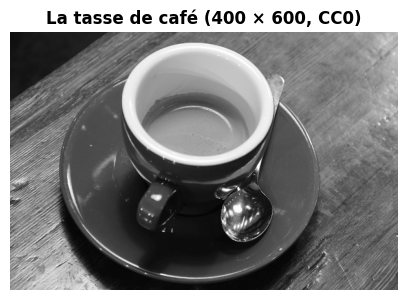

In [34]:
A_31 = wbm.datasets.load_image("tasse")      # the coffee cup: 400 × 600 grey levels (data/cards/tasse_cafe.md)
NOISE_31 = np.random.default_rng(31).normal(loc=A_31.mean(), scale=A_31.std(), size=A_31.shape)   # pure noise
plt.figure(figsize=(5, 3.4))
plt.imshow(A_31, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.title("La tasse de café (400 × 600, CC0)")
plt.show()

In [35]:
wbm.record("M12d.31a", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M12d.31b", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M12d.31c", 4, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M12d.31d", 3, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "aacd61b3c3b91ae557eb36788c489ec87c6b6b9df57c3cbf329226bdbf73061c", "id": "M12d.31a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12d.31a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "73d16c89308318ce20c82a2a98c683dfc4081c4ffb2eb40b28ae1de716ff4508", "id": "M12d.31b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12d.31b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "c48920d9da04d5871fdae2944250660c311d4a6dfcbfb32ec1c0b3001ffba254", "id": "M12d.31c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12d.31c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "cf9f0e08e232b1409fb8240242b47224577e97dd4e3c6e78cabb9a98b1414152", "id": "M12d.31d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M12d.31d : réponse enregistrée (int).


**L'expérience** (avec `np.linalg.svd`). Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

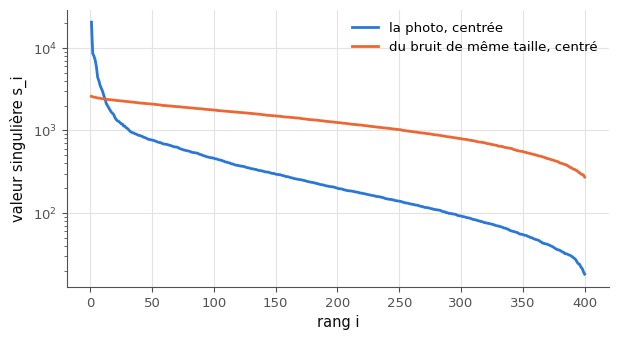

rang pour 90 % de l'énergie : photo 13, bruit 243
part de l'énergie de la photo NON centrée gardée au rang 1 : 82,5%


In [36]:
def rank_for(A, share):
    """The smallest rank k whose approximation keeps at least `share` of the energy of A − mean(A)."""
    s = np.linalg.svd(A - A.mean(), compute_uv=False)
    return int(np.searchsorted(np.cumsum(s ** 2) / np.sum(s ** 2), share) + 1)


s_photo = np.linalg.svd(A_31 - A_31.mean(), compute_uv=False)
s_noise = np.linalg.svd(NOISE_31 - NOISE_31.mean(), compute_uv=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(np.arange(1, 401), s_photo, label="la photo, centrée")
ax.semilogy(np.arange(1, 401), s_noise, label="du bruit de même taille, centré")
ax.set_xlabel("rang i")
ax.set_ylabel("valeur singulière s_i")
ax.legend()
plt.show()
s_raw = np.linalg.svd(A_31, compute_uv=False)
print(f"rang pour 90 % de l'énergie : photo {rank_for(A_31, 0.9)}, bruit {rank_for(NOISE_31, 0.9)}")
print(f"part de l'énergie de la photo NON centrée gardée au rang 1 : {s_raw[0] ** 2 / np.sum(s_raw ** 2):.1%}".replace(".", ","))

**Après l'expérience**, dans ta copie : pourquoi la photo n'a-t-elle aucune valeur singulière nulle, alors que quelques couches suffisent à la reconnaître ? Pourquoi le bruit demande-t-il presque toutes ses couches, et quel lien avec le débruitage par troncature (fiche §3, en machine learning) ? Que dit d) sur le piège de l'image non centrée ?

💡 a) Une photo a des zones lisses et des contours qui se répètent d'une ligne à l'autre : quelques couches portent l'essentiel, mais la texture fine (le grain du bois) et les arrondis des niveaux de gris donnent une longue traîne, jamais nulle. b) 13 couches gardent 90 % de l'énergie de la photo centrée. c) Le bruit n'a aucune structure : ses valeurs singulières sont du même ordre (un rapport d'environ 10 entre la première et la dernière), et il en faut environ 240 sur 400. d) Sans centrer, la première couche rend surtout le niveau moyen : 82 % de l'énergie, sans rien dire de la qualité.

### Ex M12d.32 — Compresser une image du domaine public : l'erreur en fonction du rang 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer l'énergie gardée, l'erreur et le coût de stockage d'une approximation de rang $k$ d'une photo, et regarder les reconstructions.  
**Prérequis :** fiche §3 ; Ex M12d.5 et M12d.31 · **Parcours :** C

Avec la photo `A_32` (la même qu'en M12d.31), écris :
- `reconstruct(A, k)` : l'image reconstruite au rang $k$ : on retire le niveau moyen $\bar{a}$, on prend l'approximation de rang $k$ de $\mathbf{A} - \bar{a}$ (`np.linalg.svd`, ou ta fonction `low_rank_approximation`), et l'on rajoute $\bar{a}$ ;
- `energy_kept(A)` : le tableau des parts d'énergie gardées aux rangs $1, 2, \ldots, \min(m, n)$, pour l'image **centrée** : $\sum_{i \le k} s_i^2 / \sum_i s_i^2$ (`np.cumsum`).

Puis calcule :
- a) le niveau de gris moyen $\bar{a}$ (2 décimales) ;
- b) la part d'énergie gardée au rang 10 (4 décimales) ;
- c) le plus petit rang qui garde au moins 90 % de l'énergie ;
- d) le plus petit rang qui garde au moins 99 % ;
- e) l'erreur relative $\lVert \mathbf{A} - \hat{\mathbf{A}}_{50} \rVert_F / \lVert \mathbf{A} - \bar{a} \rVert_F$, calculée **sur les matrices** avec `reconstruct` (4 décimales) ;
- f) la part des nombres stockés au rang de c), $k(m + n + 1)/(mn)$ (4 décimales) ;
- g) la part d'énergie gardée au rang 1 par l'image **non centrée** (sa SVD à elle, 4 décimales).

Une cellule affiche ensuite les reconstructions aux rangs 5, 20 et 50.

Dans ta copie : vérifie que e) est $\sqrt{1 - (\text{part gardée au rang } 50)}$, et dis pourquoi (Eckart-Young). À partir de quel rang la tasse est-elle reconnaissable ? Le grain du bois ? Combien de nombres faudrait-il pour garder 99 %, et est-ce encore une compression ? Pourquoi un JPEG fait-il beaucoup mieux (il travaille par petits blocs, et compte des bits) ?

In [37]:
A_32 = wbm.datasets.load_image("tasse")      # 400 × 600 grey levels, CC0

103.65 0.8796 13 125 0.1929 0.0542 0.825
√(1 − part au rang 50) : 0.1929


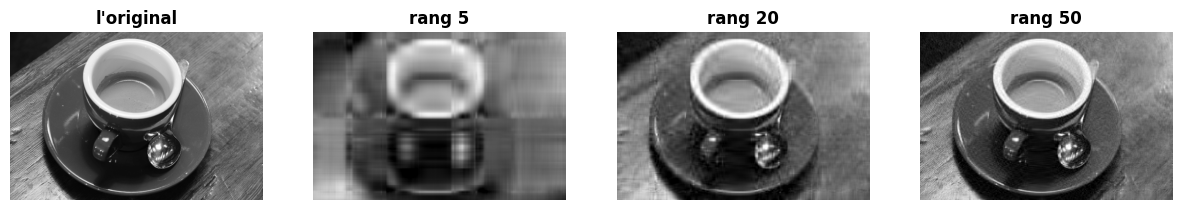

In [38]:
def reconstruct(A, k):
    """The rank-k approximation of A − mean(A), plus mean(A)."""
    mean = A.mean()
    U, s, Vt = np.linalg.svd(A - mean, full_matrices=False)
    return (U[:, :k] * s[:k]) @ Vt[:k] + mean


def energy_kept(A):
    """The shares of the energy of A − mean(A) kept at ranks 1, 2, ..., min(m, n)."""
    s = np.linalg.svd(A - A.mean(), compute_uv=False)
    return np.cumsum(s ** 2) / np.sum(s ** 2)


shares_32 = energy_kept(A_32)
m_32, n_32 = A_32.shape
answer_M12d_32a = round(float(A_32.mean()), 2)
answer_M12d_32b = round(float(shares_32[9]), 4)
answer_M12d_32c = int(np.argmax(shares_32 >= 0.90) + 1)
answer_M12d_32d = int(np.argmax(shares_32 >= 0.99) + 1)
answer_M12d_32e = round(float(np.linalg.norm(A_32 - reconstruct(A_32, 50)) / np.linalg.norm(A_32 - A_32.mean())), 4)
answer_M12d_32f = round(answer_M12d_32c * (m_32 + n_32 + 1) / (m_32 * n_32), 4)
s_raw32 = np.linalg.svd(A_32, compute_uv=False)
answer_M12d_32g = round(float(s_raw32[0] ** 2 / np.sum(s_raw32 ** 2)), 4)
print(answer_M12d_32a, answer_M12d_32b, answer_M12d_32c, answer_M12d_32d, answer_M12d_32e, answer_M12d_32f, answer_M12d_32g)
print("√(1 − part au rang 50) :", round(float(np.sqrt(1 - shares_32[49])), 4))
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, k in zip(axes, (None, 5, 20, 50)):
    ax.imshow(A_32 if k is None else np.clip(reconstruct(A_32, k), 0, 255), cmap="gray", vmin=0, vmax=255)
    ax.set_title("l'original" if k is None else f"rang {k}")
    ax.axis("off")
plt.show()

In [39]:
A_32r = wbm.datasets.load_image("tasse")
s_32r = np.linalg.svd(A_32r - A_32r.mean(), compute_uv=False)
shares_32r = np.cumsum(s_32r ** 2) / np.sum(s_32r ** 2)
raw_32r = np.linalg.svd(A_32r, compute_uv=False)
k90_32r, k99_32r = int(np.argmax(shares_32r >= 0.90) + 1), int(np.argmax(shares_32r >= 0.99) + 1)
wbm.record("M12d.32a", float(A_32r.mean()), decimals=2)
wbm.record("M12d.32b", float(shares_32r[9]), decimals=4,
           mistakes={"l'énergie se compte avec les CARRÉS des valeurs singulières": float(np.sum(s_32r[:10]) / np.sum(s_32r)),
                     "le rang 10 est le dixième élément, d'indice 9": float(shares_32r[10])})
wbm.record("M12d.32c", k90_32r,
           mistakes={"le plus petit rang k, compté à partir de 1 : l'indice NumPy plus 1": k90_32r - 1})
wbm.record("M12d.32d", k99_32r,
           mistakes={"le plus petit rang k, compté à partir de 1 : l'indice NumPy plus 1": k99_32r - 1})
wbm.record("M12d.32e", float(np.sqrt(1 - shares_32r[49])), decimals=4,
           mistakes={"l'erreur relative : divise par la norme de l'image CENTRÉE": float(np.sqrt(np.sum(s_32r[50:] ** 2)) / np.linalg.norm(A_32r)),
                     "la norme, pas son carré : prends la racine": float(1 - shares_32r[49])})
wbm.record("M12d.32f", k90_32r * 1001 / 240000, decimals=4)
wbm.record("M12d.32g", float(raw_32r[0] ** 2 / np.sum(raw_32r ** 2)), decimals=4,
           mistakes={"l'image NON centrée : la SVD de A elle-même, sans retirer la moyenne": float(shares_32r[0])})

WBM_ANSWER {"coarse_any": {"0": ["c8c30b46c23e03625e2aa5f5193a3f9b460fbc8973a5eba40289b40886bb1dd5"]}, "decimals": 2, "hash": "0170d936ac48feb924b0ab03440e92787203f6834ae4cd78878bceec51e077fe", "hash_coarse": "72e3ee83621117c5af5bbdf887558d2dcd3885bd15fc250886578f8d08a8da56", "id": "M12d.32a", "kind": "float", "magnitude": 2, "sign": 1}
📝 Ex M12d.32a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["0abba4f348de903a668d41f6af6c5fb7c705d413be579312fdc41f8d8c15be2e"], "1": ["2a57e6ba29fecc25bd094f297d5004b07c5aa386dac15510ef7b50ac64481951"]}, "coarser": {"2": ["2188004cc79bc39157e7bc381997b18508fa30df702d88d947120b232ed850e3"]}, "decimals": 4, "hash": "ce37784667273c4d427c14d51ae3f6099f265e18332dfdaf1e78a56b14cb1dc1", "hash_coarse": "3c9ffb93cee68c5b0c58285573698bcbdaa94cf943f46c00a6fe094d8bd0170a", "id": "M12d.32b", "kind": "float", "magnitude": -1, "mistakes": {"058686c9b09521ff9fcce5a429206e0f0d6fbfd1bac7bb8dbd1b11bc157a0060": "l'énergie se compte avec les 

💡 Eckart-Young : $\lVert \mathbf{A}_c - (\mathbf{A}_c)_k \rVert_F^2 = \sum_{i > k} s_i^2$, donc l'erreur relative est $\sqrt{1 - \text{part gardée}}$ ; rajouter la moyenne ne change pas l'écart. La tasse se reconnaît dès le rang 5, le grain du bois demande plusieurs dizaines de couches. 99 % demandent 125 couches, soit 52 % des nombres : la SVD globale n'est plus une compression. Un JPEG découpe l'image en blocs de $8 \times 8$, dans une base fixe (cosinus), et quantifie : il compte des bits, pas des nombres (🏆 M12d.37 pour une idée voisine).

### Ex M12d.33 — La SVD par AᵀA contre `np.linalg.svd` : ce qu'on perd quand κ est grand 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer la précision de la SVD par $\mathbf{A}^\top\mathbf{A}$ et de celle de LAPACK quand le conditionnement grandit, et voir ce qu'une bonne reconstruction cache.  
**Prérequis :** fiche §1 et §4 ; Ex M12d.26 · **Parcours :** C

La fonction `make_conditioned(kappa)` (cellule des outils) fabrique une matrice $6 \times 4$ dont les valeurs singulières, **connues**, vont de 1 à $1/\kappa$ (géométriquement) : son conditionnement est $\kappa$. Écris :
- `error_table()` : pour chaque $\kappa$ de `KAPPAS_33`, le couple des erreurs relatives sur la plus petite valeur singulière, $\lvert \hat{s}_{\min} - 1/\kappa \rvert \cdot \kappa$, obtenues par ta fonction `mymath.svd_pca.svd(A, tol=1e-12)` (pour qu'elle garde les quatre valeurs) et par `np.linalg.svd(A, compute_uv=False)`.

La cellule suivante affiche le tableau. Lis-le, puis réponds :
- a) le plus petit $\kappa$ de `KAPPAS_33` pour lequel l'erreur relative de **ta** fonction dépasse $10^{-6}$ ;
- b) vrai ou faux : l'erreur relative de `np.linalg.svd` reste sous $10^{-6}$ pour les quatre $\kappa$ ;
- c) vrai ou faux : pour $\kappa = 10^6$, ta fonction redonne quand même la matrice : $\lVert \mathbf{U}\operatorname{diag}(s)\mathbf{V}^\top - \mathbf{A} \rVert_F \le 10^{-12}\lVert \mathbf{A} \rVert_F$ (avec `tol=1e-12`) ;
- d) vrai ou faux : pour $\kappa = 10^6$, les colonnes du $\mathbf{U}$ de ta fonction sont orthonormées à $10^{-8}$ près (le plus grand écart de $\mathbf{U}^\top\mathbf{U}$ à $\mathbf{I}$) ;
- e) le nombre de valeurs singulières gardées par ta fonction **avec son seuil par défaut** pour $\kappa = 10^8$ ;
- f) `np.linalg.matrix_rank(make_conditioned(1e8))`.

Si ta fonction `svd` n'est pas encore écrite, la cellule utilise la référence et le dit.

Dans ta copie : de combien de puissances de 10 ton erreur grandit-elle quand $\kappa$ est multiplié par 100, et pourquoi (fiche §4, $\kappa^2$) ? Pourquoi c) reste-t-il vrai alors que $s_{\min}$ est faux : quelle part de $\mathbf{A}$ porte la couche fausse ? Que disent e) et f) du « rang » d'une matrice en flottants ?

In [40]:
KAPPAS_33 = [1e2, 1e4, 1e6, 1e8]       # make_conditioned(kappa) (the tools): singular values 1, ..., 1/kappa

In [41]:
mymath = wbm.load_mymath("ref")
svd_33 = mymath.svd_pca.svd


def error_table():
    """For each kappa of KAPPAS_33: (relative error on s_min of svd_33(A, tol=1e-12), the same for np.linalg.svd)."""
    rows = []
    for kappa in KAPPAS_33:
        A = make_conditioned(kappa)
        mine = svd_33(A, tol=1e-12)[1][-1]
        lapack = np.linalg.svd(A, compute_uv=False)[-1]
        rows.append((abs(mine - 1 / kappa) * kappa, abs(lapack - 1 / kappa) * kappa))
    return rows


table_33 = error_table()
print("    κ      erreur relative sur s_min : ta svd    np.linalg.svd")
for kappa, (mine, lapack) in zip(KAPPAS_33, table_33):
    print(f"{kappa:8.0e}   {mine:24.1e}   {lapack:14.1e}")
A_33 = make_conditioned(1e6)
U_33, s_33, Vt_33 = svd_33(A_33, tol=1e-12)
answer_M12d_33a = next(kappa for kappa, (mine, _) in zip(KAPPAS_33, table_33) if mine > 1e-6)
answer_M12d_33b = all(lapack < 1e-6 for _, lapack in table_33)
answer_M12d_33c = bool(np.linalg.norm(U_33 @ np.diag(s_33) @ Vt_33 - A_33) <= 1e-12 * np.linalg.norm(A_33))
answer_M12d_33d = bool(np.max(np.abs(U_33.T @ U_33 - np.eye(4))) <= 1e-8)
answer_M12d_33e = len(svd_33(make_conditioned(1e8))[1])
answer_M12d_33f = int(np.linalg.matrix_rank(make_conditioned(1e8)))
print(answer_M12d_33a, answer_M12d_33b, answer_M12d_33c, answer_M12d_33d, answer_M12d_33e, answer_M12d_33f)

    κ      erreur relative sur s_min : ta svd    np.linalg.svd
   1e+02                    1.9e-13          3.1e-15
   1e+04                    7.7e-10          2.8e-14
   1e+06                    2.9e-05          3.0e-11
   1e+08                    3.6e-01          2.1e-09
1000000.0 True True False 3 4


In [42]:
wbm.record("M12d.33a", 1e6, decimals=0,
           mistakes={"le PREMIER κ dont l'erreur DÉPASSE 1e−6, pas le dernier en dessous": 1e4,
                     "lis la colonne de TA fonction : l'erreur est relative, |ŝ − 1/κ| × κ": 1e8})
wbm.record("M12d.33b", True, mistakes={"lis la dernière colonne : LAPACK ne forme jamais AᵀA": False})
wbm.record("M12d.33c", True,
           mistakes={"U diag(s) Vᵀ avec tol=1e−12 : la couche fausse ne pèse que s_min, un millionième de A": False})
wbm.record("M12d.33d", False,
           mistakes={"U = A V / s divise par un s_min faux : UᵀU s'écarte de I d'environ 1e−16 × κ²": True})
wbm.record("M12d.33e", 3,
           mistakes={"le seuil par défaut, tol = 1e−6, retire la valeur 1e−8 (et garde 4,6e−6)": 4})
wbm.record("M12d.33f", 4,
           mistakes={"matrix_rank compare à un seuil d'environ 1e−15 × s_max : il garde 1e−8": 3})

WBM_ANSWER {"decimals": 0, "hash": "a6a26b648ab9825728ff325c416ee02f652c594c8b9053f7d210b826b3fd155d", "id": "M12d.33a", "kind": "float", "magnitude": 6, "mistakes": {"045495fbb84022273335f9e520574cff129f1c3e49a17171a5b52f3c02161a73": "lis la colonne de TA fonction : l'erreur est relative, |ŝ − 1/κ| × κ", "e443cc78bc685ed1c209f47b0f620d92b821cb6954f8b1b8a98ef068d7189166": "le PREMIER κ dont l'erreur DÉPASSE 1e−6, pas le dernier en dessous"}, "sign": 1}
📝 Ex M12d.33a : réponse enregistrée (float, 0 décimale).
WBM_ANSWER {"hash": "e02be936302fb9c82b17815ae605b4b7f18e5ae19f3f54a78818cdc5bac25179", "id": "M12d.33b", "kind": "bool", "mistakes": {"8d865aa568bd9cd655faddce35e437d42ee0b4d394de0e4322c036773a815fe3": "lis la dernière colonne : LAPACK ne forme jamais AᵀA"}}
📝 Ex M12d.33b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "2c883633e3e9be8a806d18663bdb2cc6de58d445743fcc0addc1e1c3b8dced4a", "id": "M12d.33c", "kind": "bool", "mistakes": {"4478308086e1aa0dfc092c6a4edfcd7a92c630cc087eea

💡 L'erreur sur une valeur propre de $\mathbf{A}^\top\mathbf{A}$ est d'environ $10^{-16} \times s_{\max}^2$ : sur $s_{\min}^2 = \kappa^{-2}$, une erreur relative d'environ $10^{-16}\kappa^2$, qui grandit de 4 puissances de 10 quand $\kappa$ est multiplié par 100 (pour $\kappa = 10^8$, $\kappa^2 \times 10^{-16} \approx 1$ : il ne reste rien). LAPACK travaille sur $\mathbf{A}$ et perd environ $10^{-16}\kappa$. La reconstruction reste bonne parce que la couche fausse pèse $s_{\min}\lVert \mathbf{u}\mathbf{v}^\top \rVert = 10^{-6}$ de la matrice : une SVD se juge aussi sur l'orthogonalité de $\mathbf{U}$. Le rang numérique dépend du seuil : 3 pour `svd`, 4 pour `matrix_rank`.

### Ex M12d.34 — La SVD en images : Vᵀ, Σ puis U appliqués au cercle unité, étape par étape 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner les trois étapes de la SVD d'une matrice $2 \times 2$ sur le cercle unité et ses vecteurs singuliers.  
**Prérequis :** fiche §2 ; Ex M12d.3 · **Parcours :** C, E

Écris `draw_svd_steps(axes, A)` : avec `U, s, Vt = np.linalg.svd(A)` (ou ta fonction `svd`) et 200 points $\mathbf{x}$ du cercle unité, dessine dans les quatre axes reçus (sans en ouvrir d'autres) :
1. le cercle, et les vecteurs $\mathbf{v}_1$ et $\mathbf{v}_2$ (deux flèches) ;
2. l'image du cercle par $\mathbf{V}^\top$ (encore un cercle), et les images de $\mathbf{v}_1$ et $\mathbf{v}_2$ : $\mathbf{e}_1$ et $\mathbf{e}_2$ ;
3. l'image par $\mathbf{S}\mathbf{V}^\top$ : une ellipse alignée sur les axes, de demi-axes $s_1\mathbf{e}_1$ et $s_2\mathbf{e}_2$ ;
4. l'image par $\mathbf{U}\mathbf{S}\mathbf{V}^\top = \mathbf{A}$ : l'ellipse finale, et ses demi-axes $s_1\mathbf{u}_1$ et $s_2\mathbf{u}_2$.

Colore les points du cercle selon leur angle (`ax.scatter(..., c=angles, cmap="hsv", s=6)`) pour suivre chacun d'une étape à l'autre, mets le même cadre aux quatre axes, `ax.set_aspect("equal")` et un titre par axe. La cellule de la figure s'en sert pour $\mathbf{A}$ = `[[1.5, 1.0], [-0.5, 2.0]]`.

Dans ta copie : la deuxième étape est-elle une rotation ou une symétrie ($\det\mathbf{V}$) ? Les couleurs tournent-elles dans le même sens dans le premier et le dernier dessin, et quel lien avec le signe de $\det\mathbf{A}$ ? Vérifie que l'aire de l'ellipse finale vaut $\pi\lvert\det\mathbf{A}\rvert$.

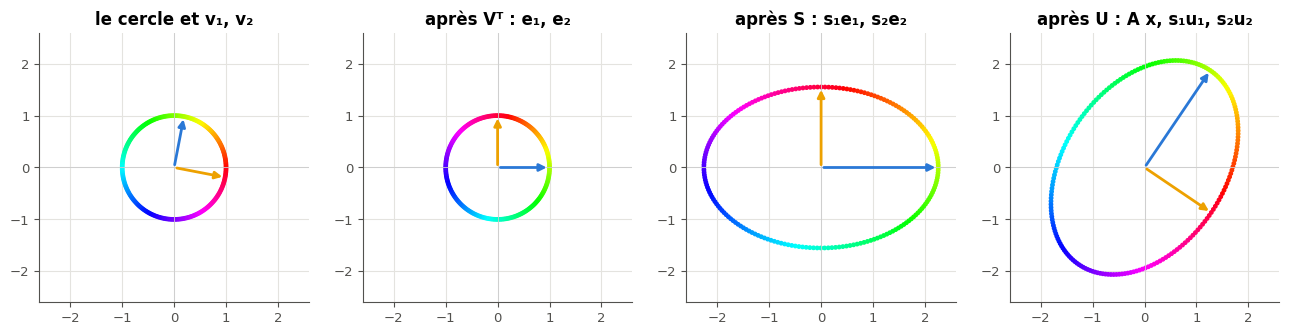

s : [2.2575, 1.5504]  det V : -1.0  det A : 3.5  π s₁ s₂ / π : 3.5


In [43]:
def draw_svd_steps(axes, A):
    """In the four axes: the unit circle, then its images by Vᵀ, by S Vᵀ and by U S Vᵀ = A, with the singular vectors."""
    U, s, Vt = np.linalg.svd(A)
    angles = np.linspace(0, 2 * np.pi, 200, endpoint=False)
    circle = np.vstack([np.cos(angles), np.sin(angles)])
    steps = [("le cercle et v₁, v₂", circle, Vt.T),
             ("après Vᵀ : e₁, e₂", Vt @ circle, np.eye(2)),
             ("après S : s₁e₁, s₂e₂", np.diag(s) @ Vt @ circle, np.diag(s)),
             ("après U : A x, s₁u₁, s₂u₂", A @ circle, U * s)]
    limit = 1.15 * max(1.0, s[0])
    for ax, (title, points, arrows) in zip(axes, steps):
        ax.scatter(points[0], points[1], c=angles, cmap="hsv", s=6)
        for column, color in zip(arrows.T, ("C0", "C3")):
            ax.annotate("", xy=column, xytext=(0, 0), arrowprops={"arrowstyle": "-|>", "color": color, "lw": 2})
        ax.axhline(0, color="0.8", lw=0.6)
        ax.axvline(0, color="0.8", lw=0.6)
        ax.set_xlim(-limit, limit)
        ax.set_ylim(-limit, limit)
        ax.set_aspect("equal")
        ax.set_title(title)


fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
try:
    draw_svd_steps(axes, np.array([[1.5, 1.0], [-0.5, 2.0]]))
except BaseException:
    plt.close(fig)
    raise
plt.show()
U_34, s_34, Vt_34 = np.linalg.svd(np.array([[1.5, 1.0], [-0.5, 2.0]]))
print("s :", np.round(s_34, 4).tolist(), " det V :", round(float(np.linalg.det(Vt_34)), 4),
      " det A :", round(float(np.linalg.det(np.array([[1.5, 1.0], [-0.5, 2.0]]))), 4), " π s₁ s₂ / π :", round(float(s_34[0] * s_34[1]), 4))

💡 $\det\mathbf{A} = 3 + 0{,}5 = 3{,}5 > 0$ : l'orientation est conservée, les couleurs tournent dans le même sens au début et à la fin ; si $\det\mathbf{V} = -1$ (cela dépend des signes rendus par LAPACK), la deuxième étape est une symétrie, et $\det\mathbf{U} = -1$ aussi. L'aire de l'ellipse est $\pi s_1s_2 = 3{,}5\,\pi$.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §3, §5 à §7. Trois erreurs à trouver dans une ACP, un test de propriétés, puis la compression d'une photo.

### Ex M12d.35 — Chasse à l'erreur : une ACP sans centrer, n et n − 1 mélangés, des axes lus en lignes au lieu de colonnes 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans une ACP écrite à la main les trois erreurs classiques, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §5 et §6 · **Parcours :** C

Un collègue a écrit cette ACP des données `X` (la cellule fournie) ; sept lignes portent une lettre et un commentaire qui dit ce qu'elles doivent calculer. Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter son code**, trouve-les.

```python
n = len(X)
mu = X.mean(axis=0)
C = X.T @ X / (n - 1)                            # (A) the covariance matrix of the data
values, vectors = np.linalg.eigh(C)              # (B) the eigenvalues, in increasing order, and the eigenvectors
order = np.argsort(values)[::-1]                 # (C) the indices, from the largest eigenvalue
variances = values[order]                        # (D) the variances along the axes, in decreasing order
axes = vectors[order]                            # (E) the principal axes, in columns, in the same order
scores = (X - mu) @ axes[:, :2]                  # (F) the scores on the first two axes
check = scores.var(axis=0)                       # (G) the variances of the scores, equal to variances[:2]
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) les bonnes variances le long des trois axes (une liste, 4 décimales) ;
- c) le bon premier axe principal, avec la convention de signe (une liste, 4 décimales) ;
- d) une fois les deux autres lignes corrigées, le rapport entre ce que calcule la ligne (G) et `variances[:2]` (le même pour les deux, 4 décimales).

Pour b) et c), écris le code corrigé dans la cellule (c'est permis : seule la recherche des lignes fausses se fait sans exécuter).

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? Laquelle donne le résultat le plus trompeur (regarde la première variance qu'elle produit), et laquelle passerait inaperçue sans la ligne (G) ? Quel contrôle simple (fiche §6, ⚠️) aurait détecté chacune ?

In [44]:
X = (np.random.default_rng(35).normal(size=(40, 3))
     @ np.array([[3.0, 1.0, 0.0], [0.0, 1.5, 0.5], [0.0, 0.0, 0.7]]) + np.array([20.0, -8.0, 4.0]))   # 40 examples

In [45]:
answer_M12d_35a = "AEG"
n = len(X)
mu = X.mean(axis=0)
C = (X - mu).T @ (X - mu) / (n - 1)              # (A) centered
values, vectors = np.linalg.eigh(C)
order = np.argsort(values)[::-1]
variances = values[order]
axes = vectors[:, order]                         # (E) the columns
axes = axes * np.where(axes[np.argmax(np.abs(axes), axis=0), np.arange(3)] < 0, -1.0, 1.0)
scores = (X - mu) @ axes[:, :2]
check = scores.var(axis=0, ddof=1)               # (G) n − 1, as the covariance
answer_M12d_35b = np.round(variances, 4).tolist()
answer_M12d_35c = np.round(axes[:, 0], 4).tolist()
answer_M12d_35d = round(float(scores.var(axis=0)[0] / variances[0]), 4)
print(answer_M12d_35a, answer_M12d_35b, answer_M12d_35c, answer_M12d_35d, " check:", np.round(check, 4).tolist())
C_wrong = X.T @ X / (n - 1)
print("ce que donne la ligne (A) fausse : première variance", round(float(np.linalg.eigvalsh(C_wrong)[-1]), 2))

AEG [11.9435, 2.5045, 0.4779] [0.9148, 0.4039, -0.0024] 0.975  check: [11.9435, 2.5045]
ce que donne la ligne (A) fausse : première variance 506.0


In [46]:
wbm.record("M12d.35a", "AEG",
           mistakes={"il manque une ligne fautive : regarde ce que mesure chaque formule : autour de quel point ?": "EG",
                     "il manque une ligne fautive : regarde comment eigh range ses vecteurs propres, et ce que sélectionne chaque indexation": "AG",
                     "il manque une ligne fautive : regarde les conventions par défaut des fonctions de NumPy": "AE",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABEG", "ACEG", "ADEG", "AEFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde ce que mesure chaque formule : autour de quel point ?": {"BEG", "CEG", "DEG", "EFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde comment eigh range ses vecteurs propres, et ce que sélectionne chaque indexation": {"ABG", "ACG", "ADG", "AFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde les conventions par défaut des fonctions de NumPy": {"ABE", "ACE", "ADE", "AEF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "E", "G"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "C", "D", "F", "AB", "AC", "AD", "AF", "BC", "BD", "BE", "BF", "BG", "CD", "CE", "CF", "CG", "DE", "DF", "DG", "EF", "FG", "ABC", "ABD", "ABF", "ACD", "ACF", "ADF", "BCD", "BCE", "BCF", "BCG", "BDE", "BDF", "BDG", "BEF", "BFG", "CDE", "CDF", "CDG", "CEF", "CFG", "DEF", "DFG", "ABCD", "ABCE", "ABCF", "ABCG", "ABDE", "ABDF", "ABDG", "ABEF", "ABFG", "ACDE", "ACDF", "ACDG", "ACEF", "ACFG", "ADEF", "ADFG", "BCDE", "BCDF", "BCDG", "BCEF", "BCEG", "BCFG", "BDEF", "BDEG", "BDFG", "BEFG", "CDEF", "CDEG", "CDFG", "CEFG", "DEFG", "ABCDE", "ABCDF", "ABCDG", "ABCEF", "ABCFG", "ABDEF", "ABDFG", "ACDEF", "ACDFG", "BCDEF", "BCDEG", "BCDFG", "BCEFG", "BDEFG", "CDEFG", "ABCDEF", "ABCDFG", "BCDEFG"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCEG", "ABDEG", "ABEFG", "ACDEG", "ACEFG", "ADEFG", "ABCDEG", "ABCEFG", "ABDEFG", "ACDEFG", "ABCDEFG"}})
X_35r = (np.random.default_rng(35).normal(size=(40, 3))
         @ np.array([[3.0, 1.0, 0.0], [0.0, 1.5, 0.5], [0.0, 0.0, 0.7]]) + np.array([20.0, -8.0, 4.0]))
C_35r = np.cov(X_35r, rowvar=False)
values_35r, vectors_35r = np.linalg.eigh(C_35r)
axis_35r = vectors_35r[:, -1] * (1.0 if vectors_35r[np.argmax(np.abs(vectors_35r[:, -1])), -1] > 0 else -1.0)
wbm.record("M12d.35b", values_35r[::-1].tolist(), decimals=4,
           mistakes={"la covariance des données CENTRÉES : corrige (A)": np.linalg.eigvalsh(X_35r.T @ X_35r / 39)[::-1].tolist(),
                     "la covariance divise par n − 1, comme np.cov": (values_35r[::-1] * 39 / 40).tolist()})
wbm.record("M12d.35c", axis_35r.tolist(), decimals=4,
           mistakes={"le premier axe est une COLONNE de vectors, la dernière (eigh range par ordre croissant)":
                         (vectors_35r[-1] * np.sign(vectors_35r[-1][np.argmax(np.abs(vectors_35r[-1]))])).tolist(),
                     "la convention de signe : la coordonnée de plus grande valeur absolue positive": (-axis_35r).tolist()})
wbm.record("M12d.35d", 39 / 40, decimals=4,
           mistakes={"np.var divise par n, la covariance par n − 1 : le rapport est (n − 1)/n, avec n = 40": 40 / 39,
                     "le commentaire de (G) se trompe : np.var divise par n par défaut, la covariance par n − 1": 1.0})

WBM_ANSWER {"hash": "6253d962b0133e9c720282fdd785d071d3a9aaf3bd78aa2b08615826bbbbf61d", "id": "M12d.35a", "kind": "str", "mistakes": {"02a46433c596122f693010abfb9688dd2a452f3cc4e4bfa01f2a45e7020499fc": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "02da7cba1ff461ab4e56aae6a827a7e65a312f1564b63359f5310071687e3691": "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple", "04316071b7788a5d658c30b0a6c8a27e8fbe1c6f2dd11a009c4b22cc6445b35a": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "04b520db90a68ac335bca504974d6b4113a2e505756b271aeab2de5da29c06b5": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0577f36a16e8bd73b852427cd7f56760dba60059643b0bea693ef68eafb69fdc": "plusieurs lignes que tu cites sont correctes

💡 (A) $\mathbf{X}^\top\mathbf{X}/(n-1)$ mesure la dispersion autour de l'**origine** : sa plus grande valeur propre (environ 506) est dominée par la moyenne $(20, -8, 4)$, et le « premier axe » pointe vers elle. (E) `vectors[order]` permute les **lignes** : il faut `vectors[:, order]`. (G) `np.var` divise par $n$ par défaut ; avec `ddof=1`, on retrouve exactement les variances : sans (G), cette incohérence passerait inaperçue. Contrôles : $\mathbf{C}\mathbf{u} = \lambda\mathbf{u}$ (attrape (E)), des scores de moyenne nulle et de variances $\lambda_j$ (attrapent (A) et (G)).

### Ex M12d.36 — Un test : la reconstruction de rang plein redonne X, et l'erreur décroît avec k 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test de propriétés pour une ACP, et vérifier qu'il attrape des erreurs plausibles.  
**Prérequis :** fiche §3 et §7 ; Ex M12d.18 ; M12b.32 (un test de propriétés) · **Parcours :** C

Un test de **propriétés** ne compare pas à des valeurs connues d'avance : il vérifie ce que tout résultat juste doit satisfaire. Écris `check_reconstruction(reconstruct, X)`, qui lève une `AssertionError` (avec `assert` ou `np.testing.assert_allclose`) si la fonction `reconstruct(X, k)`, censée rendre la reconstruction des lignes de `X` par une ACP à `k` composantes, ne vérifie pas les trois propriétés suivantes, avec $p$ le nombre de colonnes de `X`, et $e(k) = \frac{1}{n}\sum_i \lVert \mathbf{x}_i - \hat{\mathbf{x}}_i \rVert^2$ l'erreur de reconstruction moyenne :
1. **le rang plein redonne $\mathbf{X}$** : `reconstruct(X, p)` est égal à `X` à $10^{-10}$ près ;
2. **l'erreur décroît avec $k$** : $e(0) \ge e(1) \ge \cdots \ge e(p)$ (à $10^{-12}$ près) ;
3. **l'erreur est celle de la fiche** : $e(k) = \frac{n - 1}{n}\sum_{j > k}\lambda_j$ pour chaque $k$, avec $\lambda_j$ les valeurs propres de `np.cov(X, rowvar=False)` (`np.linalg.eigvalsh`, à remettre dans l'ordre décroissant), à $10^{-8}$ près relativement à la variance totale.

La cellule de vérification essaie ton test sur la bonne ACP `pca_reconstruct` (fournie) et sur trois ACP fausses : il doit accepter la première et refuser les trois autres.

Dans ta copie : laquelle des trois propriétés attrape chacune des trois ACP fausses ? La propriété 3 seule suffirait-elle, et pourquoi garder quand même les deux autres ? Quelle propriété ajouterais-tu pour tester des scores (moyenne nulle, variances $\lambda_j$, covariances nulles) ?

In [47]:
X_36 = (np.random.default_rng(36).normal(size=(30, 4))
        @ np.array([[2.0, 0.3, 0.0, 0.1], [0.0, 1.2, 0.4, 0.0], [0.0, 0.0, 0.7, 0.2], [0.0, 0.0, 0.0, 0.3]])
        + np.array([5.0, -2.0, 1.0, 7.0]))


def pca_reconstruct(X, k):
    """The reconstruction of the rows of X by a PCA with k components (eigenvectors of the covariance)."""
    mu = X.mean(axis=0)
    _, W = np.linalg.eigh(np.cov(X, rowvar=False))
    W = W[:, ::-1][:, :k]                        # the k axes of largest variance, in columns
    return mu + (X - mu) @ W @ W.T

In [48]:
def check_reconstruction(reconstruct, X):
    """Raise AssertionError unless reconstruct(X, k) behaves as a PCA reconstruction: full rank gives X back, the mean
    error e(k) does not increase with k, and e(k) = (n − 1)/n × (sum of the forgotten eigenvalues of np.cov)."""
    X = np.asarray(X, dtype=float)
    n, p = X.shape
    np.testing.assert_allclose(reconstruct(X, p), X, rtol=0, atol=1e-10)
    errors = [float(np.mean(np.sum((X - reconstruct(X, k)) ** 2, axis=1))) for k in range(p + 1)]
    assert all(later <= earlier + 1e-12 for earlier, later in zip(errors, errors[1:])), errors
    variances = np.linalg.eigvalsh(np.cov(X, rowvar=False))[::-1]
    expected = [(n - 1) / n * float(np.sum(variances[k:])) for k in range(p + 1)]
    np.testing.assert_allclose(errors, expected, rtol=0, atol=1e-8 * float(np.sum(variances)))


with checked("M12d.36 vérifications"):
    def _no_mean(X, k):                          # forgets to add the mean back
        mu = X.mean(axis=0)
        _, W = np.linalg.eigh(np.cov(X, rowvar=False))
        W = W[:, ::-1][:, :k]
        return (X - mu) @ W @ W.T

    def _increasing(X, k):                       # the columns of eigh in its (increasing) order
        mu = X.mean(axis=0)
        _, W = np.linalg.eigh(np.cov(X, rowvar=False))
        W = W[:, :k]
        return mu + (X - mu) @ W @ W.T

    def _not_centered(X, k):                     # the eigenvectors of XᵀX / (n − 1), without centering
        _, W = np.linalg.eigh(X.T @ X / (len(X) - 1))
        W = W[:, ::-1][:, :k]
        return X @ W @ W.T

    results_36 = []
    for name, function, should_pass in (("la bonne ACP, pca_reconstruct", pca_reconstruct, True),
                                        ("une ACP qui oublie de rajouter la moyenne", _no_mean, False),
                                        ("une ACP qui garde l'ordre CROISSANT de eigh", _increasing, False),
                                        ("une ACP sans centrer", _not_centered, False)):
        try:
            check_reconstruction(function, X_36.copy())
            passed = True
        except AssertionError:
            passed = False
        results_36.append(passed == should_pass)
        verdict = ("✅" if passed == should_pass else "❌") + (" ton test accepte" if passed else " ton test refuse")
        print(f"{verdict} {name}")
    if all(results_36):
        print("✅ Ex M12d.36 : ton test accepte la bonne ACP et attrape les trois erreurs.")
    else:
        print("❌ Ex M12d.36 : ton test doit accepter la bonne ACP et refuser (AssertionError) les trois autres : "
              "relis les trois propriétés de l'énoncé.")

✅ ton test accepte la bonne ACP, pca_reconstruct
✅ ton test refuse une ACP qui oublie de rajouter la moyenne
✅ ton test refuse une ACP qui garde l'ordre CROISSANT de eigh
✅ ton test refuse une ACP sans centrer
✅ Ex M12d.36 : ton test accepte la bonne ACP et attrape les trois erreurs.


💡 L'ACP sans moyenne échoue dès la propriété 1 ; celle qui garde l'ordre croissant de `eigh`, et celle qui ne centre pas, passent les propriétés 1 et 2 (des sous-espaces emboîtés donnent des erreurs décroissantes) mais échouent à la propriété 3, la seule qui dise **quel** sous-espace est choisi : elle attrape donc, seule, les trois erreurs. Les deux autres ne supposent aucun théorème, et leur échec dit où chercher. Pour des scores : moyenne nulle, variances $\lambda_j$ (avec `ddof=1`), covariances nulles (M12d.19).

### Ex M12d.37 — Défi : compresser une image centrée en gardant 93,5 % de son énergie avec au plus 5 % des nombres 🏆 ★★★ ⏱️ 30 min
**Objectif :** trouver une représentation de rang faible d'une photo plus économe que la SVD de l'image entière.  
**Prérequis :** fiche §3 et §6 ; Ex M12d.31 et M12d.32 · **Parcours :** C

La photo de la tasse (`IMAGE_37`, $400 \times 600$ niveaux de gris) a $240\,000$ pixels. **L'objectif** : écrire
- `compress(A)`, qui rend une **liste de tableaux NumPy** (la représentation compressée), et
- `decompress(parts, shape)`, qui reconstruit à partir de cette liste seule une image $\hat{\mathbf{A}}$ de forme `shape`,

de sorte que l'**énergie gardée** $1 - \lVert \mathbf{A} - \hat{\mathbf{A}} \rVert_F^2 / \lVert \mathbf{A} - \bar{a} \rVert_F^2$ (avec $\bar{a}$ le niveau de gris moyen : l'énergie de l'image **centrée**) soit d'au moins 93,5 %, avec au plus 5 % des nombres : la somme des tailles (`.size`) des tableaux rendus par `compress` ne doit pas dépasser `BUDGET_37` $= 12\,000$. Chaque tableau est de nombres sur 64 bits (`float64` ou `int64`), chaque élément comptant pour un nombre : pas de types plus petits (`uint8`, `float32`…) ni de réinterprétation d'octets (`view`, `frombuffer`, `tobytes`). La forme `shape` et les constantes écrites dans ton code (une taille, un rang) ne comptent pas ; le niveau moyen, s'il est stocké, compte pour un nombre. La vérification essaie aussi la photo retournée de gauche à droite (une compression honnête y fait aussi bien). NumPy est permis, `np.linalg.svd` et ta librairie compris ; les transformées de Fourier ou en cosinus (`np.fft`, `scipy`), scikit-learn et les bibliothèques d'images ou de compression sont interdits.

Point de départ (M12d.32) : la SVD de l'image entière centrée, au plus grand rang qui tient dans le budget ($k(m + n + 1) + 1 \le 12\,000$, soit $k = 11$), ne garde qu'environ 89 % de l'énergie. Il faut une **autre matrice** que l'image elle-même, dont les valeurs singulières décroissent plus vite. Une dernière cellule enregistre si l'objectif est atteint.

Dans ta copie : quelle matrice as-tu décomposée, et pourquoi ses valeurs singulières décroissent-elles plus vite que celles de l'image ? Comment as-tu choisi les réglages (une taille, un rang), et que gardes-tu au mieux ? Regarde ta reconstruction : quels défauts voit-on (des blocs ?), que la norme de Frobenius ne mesure pas ?

In [49]:
IMAGE_37 = wbm.datasets.load_image("tasse")       # 400 × 600 grey levels, CC0
BUDGET_37 = int(0.05 * IMAGE_37.size)               # at most 12 000 numbers

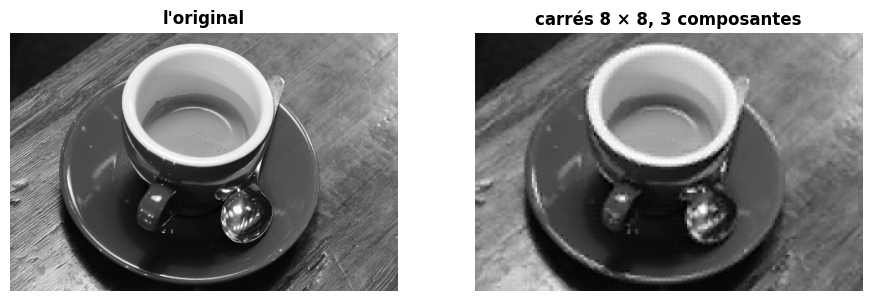

In [50]:
def compress(A):
    """A list of NumPy arrays from which decompress(parts, A.shape) rebuilds an approximation of A."""
    b, k = 8, 3                                   # 8 × 8 squares, 3 components
    m, n = A.shape
    patches = A.reshape(m // b, b, n // b, b).transpose(0, 2, 1, 3).reshape(-1, b * b)   # one square per row
    mean = patches.mean(axis=0)                   # the mean square (64 numbers)
    _, _, Vt = np.linalg.svd(patches - mean, full_matrices=False)
    return [mean, Vt[:k], (patches - mean) @ Vt[:k].T]   # 64 + 3 × 64 + 3 750 × 3 = 11 506 numbers


def decompress(parts, shape):
    """The approximation of the image of the given shape, from the list of arrays returned by compress."""
    mean, W, Z = parts
    b = int(round(np.sqrt(W.shape[1])))
    m, n = shape
    patches = Z @ W + mean
    return patches.reshape(m // b, n // b, b, b).transpose(0, 2, 1, 3).reshape(m, n)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].imshow(IMAGE_37, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("l'original")
axes[1].imshow(np.clip(decompress(compress(IMAGE_37), IMAGE_37.shape), 0, 255), cmap="gray", vmin=0, vmax=255)
axes[1].set_title("carrés 8 × 8, 3 composantes")
for ax in axes:
    ax.axis("off")
plt.show()

In [51]:
wbm.record("M12d.37", True,
           mistakes={"l'objectif n'est pas atteint : la cellule du défi dit pourquoi": False})

WBM_ANSWER {"hash": "e9e2418798738ebb85d2bcbf2cfec98ccd982e3644fca730b1bf66fe5e2c41da", "id": "M12d.37", "kind": "bool", "mistakes": {"43dd9d6d3680e38730a71dc7f03645d854f57b2451e70cc50d7227eef11ac94d": "l'objectif n'est pas atteint : la cellule du défi dit pourquoi"}}
📝 Ex M12d.37 : réponse enregistrée (bool).


In [52]:
with checked("M12d.37 défi"):
    import inspect
    import re
    problems, ok_37, ran_37 = [], False, False
    try:
        source_37 = inspect.getsource(compress) + inspect.getsource(decompress)
    except (OSError, TypeError):
        source_37 = ""
    banned_37 = sorted(set(re.findall(r"\b(fft|dct|scipy|sklearn|PIL|imageio|cv2|zlib|pickle|bz2|lzma|gzip|load_image|"
                                      r"IMAGE_37|view|frombuffer|tobytes|struct|bytes|u?int8|u?int16|u?int32|float16|"
                                      r"float32|half|single)\b", source_37)))
    if banned_37:
        ran_37 = True
        problems.append(f"compress ou decompress utilise {', '.join(banned_37)}, interdit dans ce défi")
    images_37 = [("la photo", IMAGE_37), ("la photo retournée de gauche à droite", IMAGE_37[:, ::-1].copy())]
    for name_t, A_t in (images_37 if not banned_37 else ()):
        try:
            parts_t = list(compress(A_t.copy()))
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            ran_37 = True
            problems.append(f"compress lève {type(exc).__name__} ({exc})")
            break
        ran_37 = True
        arrays_t = [np.asarray(part) for part in parts_t]
        if not arrays_t or not all((np.issubdtype(a.dtype, np.integer) or np.issubdtype(a.dtype, np.floating))
                                   and a.dtype.itemsize == 8 for a in arrays_t):
            problems.append("compress doit rendre une liste de tableaux NumPy de nombres sur 64 bits (float64 ou int64)")
            break
        count_t = sum(a.size for a in arrays_t)
        try:
            B_t = np.asarray(decompress([a.copy() for a in arrays_t], A_t.shape), dtype=float)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"decompress lève {type(exc).__name__} ({exc})")
            break
        if B_t.shape != A_t.shape:
            problems.append(f"decompress rend la forme {B_t.shape}, pas {A_t.shape}")
            break
        kept_t = 1 - float(np.sum((A_t - B_t) ** 2) / np.sum((A_t - A_t.mean()) ** 2))
        print(f"{name_t} : {count_t} nombres ({count_t / A_t.size:.2%}), énergie gardée {kept_t:.2%}".replace(".", ","))
        if count_t > BUDGET_37:
            problems.append(f"{name_t} : {count_t} nombres stockés, au-dessus du budget de {BUDGET_37}")
        if not kept_t >= 0.935:
            problems.append(f"{name_t} : {kept_t:.2%} de l'énergie gardée, sous les 93,5 %".replace(".", ","))
        if problems:
            break
    if problems:
        print("❌ Ex M12d.37 : " + " ; ".join(problems) + ".")
    elif ran_37:
        ok_37 = True
        print("✅ Ex M12d.37 : défi réussi : au moins 93,5 % de l'énergie avec au plus 5 % des nombres, sur les deux images.")

la photo : 11506 nombres (4,79%), énergie gardée 94,10%
la photo retournée de gauche à droite : 11506 nombres (4,79%), énergie gardée 94,10%
✅ Ex M12d.37 : défi réussi : au moins 93,5 % de l'énergie avec au plus 5 % des nombres, sur les deux images.


💡 L'idée : découper l'image en carrés de $8 \times 8$ pixels, et ranger chaque carré en ligne d'une matrice de forme $(3\,750, 64)$. Les carrés se ressemblent (des zones lisses, des bords, du grain) : cette matrice a des valeurs singulières qui décroissent bien plus vite que celles de l'image, et son ACP (fiche §6 : centrer par le carré moyen, puis la SVD) garde 94 % de l'énergie avec 3 composantes, pour $64 + 3 \times 64 + 3\,750 \times 3 = 11\,506$ nombres. Des carrés de $10 \times 10$ ou $20 \times 20$ font presque aussi bien. Des tuiles $50 \times 50$ décomposées chacune par sa propre SVD, au rang choisi au mieux, ne dépassent pas 90 % : leurs bases ne sont pas partagées. La seule moyenne de chaque rectangle de $4 \times 5$ pixels (tout le budget) garde 93,3 % : d'où l'objectif de 93,5 %. Les défauts visibles sont des bords de carrés : JPEG les atténue, et compte des bits plutôt que des nombres.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer la SVD d'une petite matrice par AᵀA, et l'interpréter comme rotation, étirement, rotation ?
2. Sais-tu calculer une approximation de rang faible, son erreur et son coût de stockage ?
3. Sais-tu calculer une pseudo-inverse et un conditionnement, et dire ce qu'ils signifient ?
4. Sais-tu faire une ACP à la main (covariance, axes, scores, reconstruction) et lire une variance expliquée ?
5. Sais-tu dire ce que t-SNE et UMAP gardent, et ce qu'une de leurs cartes ne permet pas de conclure ?

**La suite** : le chapitre 12 de workbookIA (préparation des données), puis M13a, vraisemblance et régression logistique.